# Una granja eólica como grafo: GNN para predecir la potencia de cada turbina con efecto de estelas

**Resumen del cuaderno.** El objetivo es predecir la potencia de cada turbina de un parque teniendo en cuenta las estelas, y decidir cuándo una red neuronal de grafos (GNN) merece la pena. Se comparan la curva de potencia sin estelas, el modelo clásico de Jensen/Park, un MLP (perceptrón multicapa, *multilayer perceptron*) y una GNN con paso de mensajes escrito a mano, con SCADA (sistema de supervisión, control y adquisición de datos de la turbina) real de Penmanshiel y Kelmarsh y con un banco sintético de granjas con verdad conocida. Resultados principales: en el mismo parque y en meses no vistos los modelos aprendidos ganan (77 kW de MAE (error absoluto medio) por turbina la GNN frente a 80 kW el MLP y 104 kW Jensen), pero en un parque nuevo gana Jensen (84 kW frente a 110 a 120 kW de la GNN), porque con un solo parque de entrenamiento la GNN aprende el parque. En el banco sintético la GNN generaliza si ve varias geometrías y la física real es más rica que Jensen, y pierde con física sencilla; en Kelmarsh empieza a ganar al ajustar con unos 3 meses de datos locales.

**Objetivo de la sesión.** Predecir la potencia de cada turbina de un parque a partir de las condiciones de viento del parque, teniendo en cuenta que unas turbinas quitan viento a otras (estelas). Lo haremos con cuatro métodos y los compararemos con datos reales de SCADA:

| | Método | Qué sabe de las estelas |
|---|---|---|
| (a) | Curva de potencia del parque, sin estelas | Nada |
| (b) | Modelo clásico de estelas Jensen/Park | Física simplificada con un parámetro $k$ (coeficiente de decaimiento de la estela) |
| (c) | MLP con el vector de todas las turbinas | Lo que aprenda de los datos, pero atado al número y al orden de turbinas |
| (d) | Red neuronal de grafos (GNN) con paso de mensajes escrito a mano | Lo que aprenda de los datos, a partir de la geometría relativa entre turbinas |

**Qué vas a aprender**

1. Cómo representar un parque como un **grafo dinámico**: los nodos son turbinas y las aristas dependen de la dirección del viento.
2. Qué hace realmente una GNN: **mensaje, agregación y actualización**, con tensores de PyTorch y sin librerías de grafos.
3. Cómo evaluar con honestidad: test temporal (meses no vistos) y test en **otro parque con otra disposición**.
4. **Cuándo merece la pena una GNN y cuándo no**, con un banco de pruebas sintético con verdad conocida y un mapa de decisión (secciones 14 a 21).

**Aviso desde el principio.** Este notebook no está diseñado para que gane la GNN. Los resultados son los que salen al ejecutarlo, y en la discusión final se comentan tal cual, incluso cuando un método sencillo es tan bueno o mejor.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/wind_cases/02_gnn_granja_eolica_estelas.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta y descarga la carpeta `datos/` del repositorio. En un entorno de CPU gratuito de Colab (2 núcleos, sin GPU) el cuaderno completo tarda unos 2 min medidos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan y, en Colab,
# descarga la carpeta datos/ (unos 22 MB) del repositorio del curso si no está junto al cuaderno.
import importlib.util, os, shutil, subprocess, sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'torch': 'torch',
    'pyarrow': 'pyarrow',
}  # nombre de importación -> requisito de pip
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], check=True)

REPO = 'https://github.com/fborbon/academy.git'         # repositorio del curso (carpeta neural-networks-1002/wind_cases)
if not Path('datos').exists():
    print('Descargando datos/ del repositorio del curso ...')
    tmp = Path('_repo_curso')
    shutil.rmtree(tmp, ignore_errors=True)
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse', REPO, str(tmp)], check=True)
    subprocess.run(['git', '-C', str(tmp), 'sparse-checkout', 'set', 'neural-networks-1002/wind_cases/datos'], check=True)
    shutil.copytree(tmp / 'neural-networks-1002' / 'wind_cases' / 'datos', 'datos')
    shutil.rmtree(tmp, ignore_errors=True)
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()} | datos/: {len(list(Path('datos').glob('*')))} archivos")

Entorno: Python 3.12.3 | local | CPUs: 8 | datos/: 20 archivos


<!-- toc -->
**Contenido**

* [1. Entorno y semillas](#1.-Entorno-y-semillas)
* [2. Los datos: dos parques reales con SCADA de 10 minutos](#2.-Los-datos:-dos-parques-reales-con-SCADA-de-10-minutos)
* [3. De tabla larga a matrices tiempo × turbina, y dirección del parque](#3.-De-tabla-larga-a-matrices-tiempo-×-turbina,-y-dirección-del-parque)
* [4. La geometría depende del viento: un grafo dinámico](#4.-La-geometría-depende-del-viento:-un-grafo-dinámico)
* [5. Viento libre del parque y curva de potencia (método a)](#5.-Viento-libre-del-parque-y-curva-de-potencia-%28método-a%29)
* [6. Método (b): modelo de estelas Jensen/Park](#6.-Método-%28b%29:-modelo-de-estelas-Jensen/Park)
* [7. Preparar tensores para los modelos de aprendizaje](#7.-Preparar-tensores-para-los-modelos-de-aprendizaje)
* [8. Método (c): MLP con el vector de todas las turbinas](#8.-Método-%28c%29:-MLP-con-el-vector-de-todas-las-turbinas)
* [9. Método (d): la GNN, paso de mensajes escrito a mano](#9.-Método-%28d%29:-la-GNN,-paso-de-mensajes-escrito-a-mano)
* [10. Entrenamiento con parada temprana](#10.-Entrenamiento-con-parada-temprana)
* [11. Test 1: meses no vistos en Penmanshiel](#11.-Test-1:-meses-no-vistos-en-Penmanshiel)
* [12. Test 2: otro parque que el modelo no ha visto (Kelmarsh)](#12.-Test-2:-otro-parque-que-el-modelo-no-ha-visto-%28Kelmarsh%29)
* [13. Pérdida por estelas por sector de dirección](#13.-Pérdida-por-estelas-por-sector-de-dirección)
* [14. ¿Cuándo merece la pena una GNN y cuándo no?](#14.-¿Cuándo-merece-la-pena-una-GNN-y-cuándo-no?)
* [15. Un simulador de granjas con verdad conocida](#15.-Un-simulador-de-granjas-con-verdad-conocida)
* [16. Experimento 1: granjas y direcciones nunca vistas, con física rica](#16.-Experimento-1:-granjas-y-direcciones-nunca-vistas,-con-física-rica)
* [17. Experimento 2: ¿cuántos layouts hacen falta?](#17.-Experimento-2:-¿cuántos-layouts-hacen-falta?)
* [18. Experimento 3: si la física es sencilla y bien conocida](#18.-Experimento-3:-si-la-física-es-sencilla-y-bien-conocida)
* [19. Experimento 4: ablaciones, ¿qué partes de la GNN importan?](#19.-Experimento-4:-ablaciones,-¿qué-partes-de-la-GNN-importan?)
* [20. Experimento 5: vuelta al caso real, Kelmarsh con unas semanas de datos locales](#20.-Experimento-5:-vuelta-al-caso-real,-Kelmarsh-con-unas-semanas-de-datos-locales)
* [21. Mapa de decisión: cuándo usar una GNN y cuándo no](#21.-Mapa-de-decisión:-cuándo-usar-una-GNN-y-cuándo-no)
* [22. Discusión de la primera parte, limitaciones, extensión física y ejercicios](#22.-Discusión-de-la-primera-parte,-limitaciones,-extensión-física-y-ejercicios)

*Para saltar a una sección usa el índice del panel lateral izquierdo: en JupyterLab la pestaña "Table of Contents" y en VS Code la vista "Outline" (se generan solas a partir de los títulos). Los enlaces de esta lista llevan bien a las secciones cercanas, pero JupyterLab no siempre llega a las lejanas porque no dibuja todas las celdas a la vez.*


## 1. Entorno y semillas

Fijamos semillas para que los resultados sean reproducibles en CPU (unidad central de procesamiento). Todo el notebook debería ejecutarse en unos 10 minutos en CPU.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEMILLA = 0
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATOS = Path("datos")
T0 = time.time()  # para medir el tiempo total de ejecución
print("torch", torch.__version__)

torch 2.15.0+cpu



## 2. Los datos: dos parques reales con SCADA de 10 minutos

Usamos dos conjuntos de datos abiertos publicados en Zenodo con licencia **CC BY 4.0 (Creative Commons Atribución)**:

- **Penmanshiel** (Escocia): 14 turbinas de 2,05 MW, rotor $D = 82$ m, terreno ondulado. DOI [10.5281/zenodo.5946808](https://doi.org/10.5281/zenodo.5946808).
- **Kelmarsh** (Inglaterra): 6 turbinas de 2,05 MW, rotor $D = 92$ m, terreno suave. DOI [10.5281/zenodo.5841834](https://doi.org/10.5281/zenodo.5841834).

Del SCADA bruto (un CSV por turbina y año) hemos extraído, para 2018 y 2019, la potencia activa, la velocidad de viento del anemómetro de góndola, la dirección absoluta del viento de cada turbina (posición de la góndola más ángulo de la veleta) y la temperatura ambiente de la góndola. Filtros aplicados al crear el extracto `datos/gnn_scada_penmanshiel_kelmarsh_30min.parquet` (unos 5 MB):

1. Solo instantes de 10 minutos en los que **todas** las turbinas del parque informan potencia, viento y dirección. Si sumáramos sin este filtro, una turbina sin datos contaría como 0 MW y parecería una pérdida.
2. Se descartan los instantes en que alguna turbina está parada ($P < 10$ kW) con viento de góndola $> 4{,}5$ m/s: son paradas o mantenimiento, no estelas.
3. Submuestreo: un instante de cada tres (uno cada 30 minutos), para que todo corra en CPU en minutos.

**Plan de uso.** Entrenamos con **Penmanshiel** (más turbinas, más pares con estela) y probamos (1) en Penmanshiel en meses posteriores y (2) en **Kelmarsh**, un parque que el modelo no ha visto nunca, con otro número de turbinas y otra disposición.

In [2]:
scada = pd.read_parquet(DATOS / "gnn_scada_penmanshiel_kelmarsh_30min.parquet")
turbinas = pd.read_csv(DATOS / "gnn_turbinas.csv")

print(scada.shape)
print(scada.groupby("granja", observed=True).agg(filas=("potencia_kw", "size"),
                                                 desde=("timestamp", "min"), hasta=("timestamp", "max")))
turbinas[["granja", "turbina", "diametro_m", "altura_buje_m", "potencia_nominal_kw", "elevacion_m"]].head(8)

(626912, 7)
              filas               desde               hasta
granja                                                     
kelmarsh     199842 2018-01-01 00:00:00 2019-12-31 23:30:00
penmanshiel  427070 2018-01-01 03:00:00 2019-12-31 23:30:00


,granja,turbina,diametro_m,altura_buje_m,potencia_nominal_kw,elevacion_m
0,kelmarsh,Kelmarsh_01,92.0,78.5,2050.0,145.598
1,kelmarsh,Kelmarsh_02,92.0,78.5,2050.0,156.577
2,kelmarsh,Kelmarsh_03,92.0,68.5,2050.0,153.477
3,kelmarsh,Kelmarsh_04,92.0,78.5,2050.0,146.313
4,kelmarsh,Kelmarsh_05,92.0,78.5,2050.0,142.901
5,kelmarsh,Kelmarsh_06,92.0,68.5,2050.0,135.039
6,penmanshiel,Penmanshiel_01,82.0,59.0,2050.0,212.260
7,penmanshiel,Penmanshiel_02,82.0,59.0,2050.0,200.460



## 3. De tabla larga a matrices tiempo × turbina, y dirección del parque

Para cada parque construimos matrices $P_{t,i}$ (potencia), $U_{t,i}$ (viento de góndola) y $\theta_{t,i}$ (dirección) con $t$ = instante e $i$ = turbina. Las posiciones (latitud, longitud) se pasan a metros en un plano local.

La dirección del parque en cada instante es la **media circular** de las direcciones de todas las turbinas (no se puede promediar ángulos directamente: la media de 350° y 10° es 0°, no 180°):

$$\bar\theta_t = \operatorname{atan2}\Big(\sum_i \sin\theta_{t,i},\; \sum_i \cos\theta_{t,i}\Big)$$

La temperatura del parque es la mediana entre turbinas y con ella estimamos la densidad del aire con la ley de los gases ideales y una presión que baja con la altitud $z$:

$$\rho = \frac{p_0\, e^{-z/8434}}{R_d\,(T + 273{,}15)}, \qquad p_0 = 101325 \text{ Pa},\; R_d = 287{,}05 \text{ J/(kg K)}$$

In [3]:
def preparar_granja(nombre):
    """Devuelve un diccionario con matrices (T, N) y la geometría del parque."""
    g = scada[scada.granja == nombre].copy()
    g["turbina"] = g.turbina.astype(str)
    t = turbinas[turbinas.granja == nombre].sort_values("turbina").reset_index(drop=True)
    piv = lambda col: g.pivot(index="timestamp", columns="turbina", values=col)[t.turbina]
    P, U, WD, TEMP = (piv(c) for c in ["potencia_kw", "viento_ms", "direccion_deg", "temp_c"])

    # posiciones en metros respecto al centro del parque (aproximación plana, válida a pocos km)
    lat0, lon0 = t.lat.mean(), t.lon.mean()
    este = (t.lon - lon0).values * 111320 * np.cos(np.deg2rad(lat0))
    norte = (t.lat - lat0).values * 110540

    # dirección del parque: media circular de las direcciones de todas las turbinas
    r = np.deg2rad(WD.values)
    theta = np.rad2deg(np.arctan2(np.sin(r).sum(1), np.cos(r).sum(1))) % 360

    # temperatura del parque (mediana) y densidad del aire
    temp = TEMP.median(axis=1).ffill().bfill().values
    z = (t.elevacion_m + t.altura_buje_m).mean()
    rho = 101325 * np.exp(-z / 8434) / (287.05 * (temp + 273.15))

    return dict(nombre=nombre, tiempo=P.index, turbinas=list(t.turbina),
                P=P.values.astype(np.float32), U=U.values.astype(np.float32), theta=theta, rho=rho,
                xy=np.c_[este, norte], D=float(t.diametro_m.iloc[0]),
                P_nom=float(t.potencia_nominal_kw.iloc[0]))

pen = preparar_granja("penmanshiel")
kel = preparar_granja("kelmarsh")
for f in (pen, kel):
    print(f"{f['nombre']:12s} instantes={len(f['tiempo']):6d} turbinas={len(f['turbinas']):2d} "
          f"D={f['D']:.0f} m  densidad media={f['rho'].mean():.3f} kg/m3")

penmanshiel  instantes= 30505 turbinas=14 D=82 m  densidad media=1.210 kg/m3
kelmarsh     instantes= 33307 turbinas= 6 D=92 m  densidad media=1.208 kg/m3



## 4. La geometría depende del viento: un grafo dinámico

Para un par de turbinas $j \to i$ calculamos, con la dirección $\bar\theta_t$ de cada instante, dos coordenadas en el **sistema de referencia del viento**, normalizadas por el diámetro $D$:

- $x_{ji}$: distancia **aguas abajo** de $j$ a $i$ (positiva si $i$ está detrás de $j$ según sopla el viento).
- $y_{ji}$: desplazamiento **transversal** (perpendicular al viento).

Si $\bar\theta$ es la dirección *de la que viene* el viento (convención meteorológica, 0° = norte), el viento avanza hacia el vector unitario $\mathbf{e} = (-\sin\bar\theta, -\cos\bar\theta)$ en coordenadas (este, norte). Con $\Delta\mathbf{p} = \mathbf{p}_i - \mathbf{p}_j$:

$$x_{ji} = \frac{\Delta\mathbf{p}\cdot\mathbf{e}}{D}, \qquad y_{ji} = \frac{\Delta\mathbf{p}\cdot\mathbf{e}_\perp}{D}, \qquad \mathbf{e}_\perp = (-e_y, e_x)$$

**Aristas.** Creamos una arista dirigida $j \to i$ solo si $i$ puede estar en la estela de $j$: $0 < x_{ji} \le 20$ y $|y_{ji}| \le 4$. Como $x$ e $y$ cambian con la dirección, **el conjunto de aristas cambia en cada instante**: es un grafo dinámico. La misma turbina puede ser emisora con viento del oeste y receptora con viento del este.

Llamamos **turbina libre** a la que no tiene ninguna turbina delante en un cono de ±30° hasta 15 $D$ (el mismo criterio se usa en estudios de calibración de estelas con SCADA).

In [4]:
def geometria(xy, theta_deg, D):
    """x[t, j, i], y[t, j, i]: posición de la turbina i respecto a j en el sistema del viento, en diámetros."""
    th = np.deg2rad(np.atleast_1d(theta_deg))[:, None, None]
    ex, ey = -np.sin(th), -np.cos(th)                 # hacia dónde sopla el viento
    dx = xy[None, :, 0] - xy[:, None, 0]              # dx[j, i] = este_i - este_j
    dy = xy[None, :, 1] - xy[:, None, 1]
    x = (dx[None] * ex + dy[None] * ey) / D           # aguas abajo
    y = (dx[None] * (-ey) + dy[None] * ex) / D        # transversal
    return x.astype(np.float32), y.astype(np.float32)

def mascara_aristas(x, y, x_max=20.0, y_max=4.0):
    """1 si existe la arista j -> i (i está aguas abajo de j y cerca de su eje)."""
    return ((x > 0) & (x <= x_max) & (np.abs(y) <= y_max)).astype(np.float32)

def turbinas_libres(x, y, x_max=15.0, cono_deg=30.0):
    """libre[t, i] = True si ninguna turbina j tiene a i dentro de su cono de estela."""
    en_cono = (x > 0) & (x <= x_max) & (np.abs(y) <= x * np.tan(np.deg2rad(cono_deg)))
    return ~en_cono.any(axis=1)

for f in (pen, kel):
    f["gx"], f["gy"] = geometria(f["xy"], f["theta"], f["D"])
    f["M"] = mascara_aristas(f["gx"], f["gy"])
    f["libre"] = turbinas_libres(f["gx"], f["gy"])
    print(f"{f['nombre']:12s} aristas por instante: media={f['M'].sum((1, 2)).mean():.1f} "
          f"(máximo posible {len(f['turbinas']) * (len(f['turbinas']) - 1)}), "
          f"turbinas libres por instante: media={f['libre'].sum(1).mean():.1f}")

penmanshiel  aristas por instante: media=29.9 (máximo posible 182), turbinas libres por instante: media=4.6
kelmarsh     aristas por instante: media=9.3 (máximo posible 30), turbinas libres por instante: media=3.1


Veamos el grafo de Penmanshiel con dos direcciones de viento distintas. Las flechas son las aristas $j \to i$ que la GNN usará para pasar mensajes; las turbinas en verde son las libres.

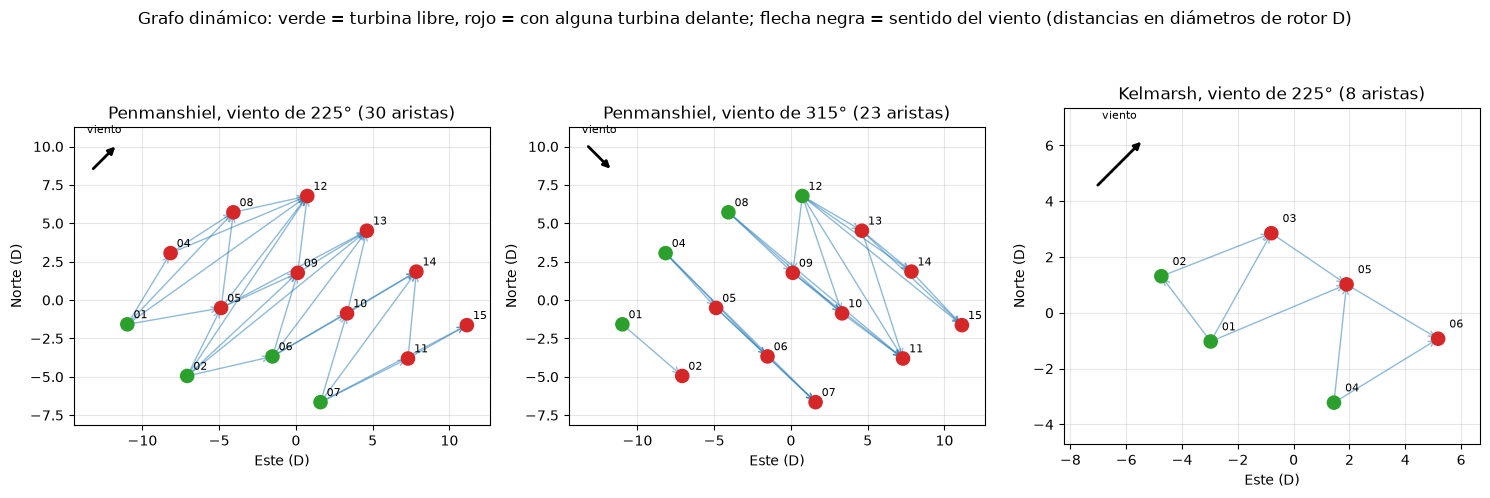

In [5]:
def dibujar_grafo(ax, f, theta):
    x, y = geometria(f["xy"], theta, f["D"])
    M, libre = mascara_aristas(x, y)[0], turbinas_libres(x, y)[0]
    p = f["xy"] / f["D"]
    for j, i in zip(*np.nonzero(M)):
        ax.annotate("", xy=p[i], xytext=p[j],
                    arrowprops=dict(arrowstyle="->", color="tab:blue", alpha=0.5, lw=1))
    ax.scatter(p[:, 0], p[:, 1], s=90, c=np.where(libre, "tab:green", "tab:red"), zorder=3)
    for k, nombre in enumerate(f["turbinas"]):
        ax.text(p[k, 0] + 0.4, p[k, 1] + 0.4, nombre.split("_")[1], fontsize=8)
    # flecha que indica hacia dónde sopla el viento
    e = np.array([-np.sin(np.deg2rad(theta)), -np.cos(np.deg2rad(theta))])
    c = np.array([p[:, 0].min() - 1.5, p[:, 1].max() + 2.5])      # esquina superior izquierda
    ax.annotate("", xy=c + 1.2 * e, xytext=c - 1.2 * e, arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
    ax.text(c[0], c[1] + 1.6, "viento", ha="center", fontsize=8)
    ax.set_xlim(p[:, 0].min() - 3.5, p[:, 0].max() + 1.5)
    ax.set_ylim(p[:, 1].min() - 1.5, p[:, 1].max() + 4.5)
    ax.set_title(f"{f['nombre'].capitalize()}, viento de {theta:.0f}° ({int(M.sum())} aristas)")
    ax.set_xlabel("Este (D)")
    ax.set_ylabel("Norte (D)")
    ax.set_aspect("equal")

fig, axs = plt.subplots(1, 3, figsize=(15, 5.2))
dibujar_grafo(axs[0], pen, 225)
dibujar_grafo(axs[1], pen, 315)
dibujar_grafo(axs[2], kel, 225)
fig.suptitle("Grafo dinámico: verde = turbina libre, rojo = con alguna turbina delante; "
             "flecha negra = sentido del viento (distancias en diámetros de rotor D)")
plt.tight_layout()
plt.show()


## 5. Viento libre del parque y curva de potencia (método a)

Necesitamos una velocidad de entrada que **no** esté ya afectada por la estela de cada turbina. Usamos el **viento libre estimado** $U_\infty(t)$: la media del viento de góndola de las turbinas libres en ese instante.

$$U_\infty(t) = \frac{1}{|\mathcal{L}_t|}\sum_{i \in \mathcal{L}_t} U_{t,i}$$

Con $U_\infty$ ajustamos una **curva de potencia del parque** usando solo turbinas libres y solo meses de entrenamiento: mediana de la potencia por intervalos de 0,5 m/s, forzada a ser creciente. El método (a) predice simplemente $\hat P_{t,i} = P_c(U_\infty(t))$ para todas las turbinas: ignora las estelas.

Todos los demás métodos predicen un **cociente** respecto a esa curva:

$$\hat P_{t,i} = r_{t,i}\; P_c\big(U_\infty(t)\big)$$

donde $r_{t,i} \approx 1$ para una turbina libre y $r_{t,i} < 1$ para una turbina en la estela. Esta elección hace que el modelo aprenda la parte de **estelas** y no la curva de potencia, que es distinta en cada parque (aquí el rotor de Kelmarsh es más grande). Para Kelmarsh, la curva se ajusta con sus datos de **2018** y la evaluación se hace en **2019**: es lo que tendría un operador (o una curva del fabricante) antes de aplicar un modelo de estelas.

**Particiones.**

- Penmanshiel, entrenamiento: enero 2018 a marzo 2019. Validación (parada temprana): abril a junio 2019. **Test temporal**: julio a diciembre 2019.
- Kelmarsh: 2018 solo para su curva de potencia; **test de otro parque**: todo 2019.

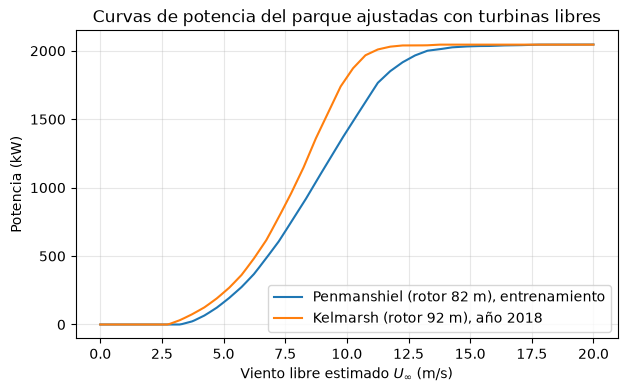

In [6]:
for f in (pen, kel):
    L = f["libre"]
    f["U_inf"] = (f["U"] * L).sum(1) / np.maximum(L.sum(1), 1)

pen["tr"] = pen["tiempo"] < "2019-04-01"
pen["va"] = (pen["tiempo"] >= "2019-04-01") & (pen["tiempo"] < "2019-07-01")
pen["te"] = pen["tiempo"] >= "2019-07-01"
kel["cal"] = kel["tiempo"] < "2019-01-01"
kel["te"] = kel["tiempo"] >= "2019-01-01"

BINS = np.arange(0, 25.01, 0.5)

def ajustar_curva(f, filas):
    """Curva de potencia del parque P_c(U_inf) con turbinas libres en las filas indicadas."""
    u = np.repeat(f["U_inf"][filas], len(f["turbinas"]))
    p = f["P"][filas].ravel()
    libre = f["libre"][filas].ravel()
    u, p = u[libre], p[libre]
    centros, medianas = [], []
    for a, b in zip(BINS[:-1], BINS[1:]):
        sel = (u >= a) & (u < b)
        if sel.sum() >= 20:
            centros.append((a + b) / 2)
            medianas.append(np.median(p[sel]))
    medianas = np.maximum.accumulate(np.clip(medianas, 0, None))   # creciente
    return lambda v: np.interp(v, centros, medianas, left=0.0, right=medianas[-1]).astype(np.float32)

pen["curva"] = ajustar_curva(pen, pen["tr"])
kel["curva"] = ajustar_curva(kel, kel["cal"])
for f in (pen, kel):
    f["P_c"] = f["curva"](f["U_inf"])   # potencia sin estelas para cada instante (T,)

uu = np.linspace(0, 20, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(uu, pen["curva"](uu), label="Penmanshiel (rotor 82 m), entrenamiento")
ax.plot(uu, kel["curva"](uu), label="Kelmarsh (rotor 92 m), año 2018")
ax.set_xlabel("Viento libre estimado $U_\\infty$ (m/s)")
ax.set_ylabel("Potencia (kW)")
ax.set_title("Curvas de potencia del parque ajustadas con turbinas libres")
ax.legend()
plt.show()

**Métricas.** Para cada método calculamos sobre el periodo de test:

- **MAE y RMSE (raíz del error cuadrático medio) por turbina** (kW): sobre todos los pares (instante, turbina).
- **MAE y RMSE del parque** (kW): sobre la suma de potencias del parque en cada instante.
- **Pérdida por estelas por sector** de dirección, frente a la medida:

$$\text{pérdida}_s = 1 - \frac{\sum_{t \in s}\sum_i P_{t,i}}{\sum_{t \in s} N\, P_c(U_\infty(t))}$$

calculada solo con $5 \le U_\infty \le 11$ m/s (por debajo de la nominal, donde la estela cuesta energía). La versión "medida" usa $P$ real y la de cada modelo usa $\hat P$.

In [7]:
def metricas(f, P_hat, filas):
    """MAE y RMSE (kW) por turbina y del parque en las filas indicadas."""
    P, Ph = f["P"][filas], P_hat[filas]
    e_t = Ph - P
    e_g = Ph.sum(1) - P.sum(1)
    return {"MAE turbina (kW)": np.abs(e_t).mean(), "RMSE turbina (kW)": np.sqrt((e_t ** 2).mean()),
            "MAE parque (kW)": np.abs(e_g).mean(), "RMSE parque (kW)": np.sqrt((e_g ** 2).mean())}

SECTORES = np.arange(0, 360, 30)

def perdida_por_sector(f, P_hat, filas):
    sel = filas & (f["U_inf"] >= 5) & (f["U_inf"] <= 11)
    sector = ((f["theta"] + 15) % 360 // 30 * 30).astype(int)
    N = len(f["turbinas"])
    out = {}
    for s in SECTORES:
        m = sel & (sector == s)
        out[s] = (1 - P_hat[m].sum() / (N * f["P_c"][m].sum())) * 100 if m.sum() > 30 else np.nan
    return pd.Series(out)

resultados = {}   # (test, método) -> métricas
predicciones = {"pen": {}, "kel": {}}

def registrar(clave, metodo, f, P_hat, filas):
    predicciones[clave][metodo] = P_hat
    resultados[(clave, metodo)] = metricas(f, P_hat, filas)

for clave, f in (("pen", pen), ("kel", kel)):
    registrar(clave, "(a) curva sin estelas", f, np.repeat(f["P_c"][:, None], len(f["turbinas"]), 1), f["te"])
pd.DataFrame(resultados).T.round(1)

,,MAE turbina (kW),RMSE turbina (kW),MAE parque (kW),RMSE parque (kW)
pen,(a) curva sin estelas,113.599998,185.600006,977.799988,1539.900024
kel,(a) curva sin estelas,116.000000,196.500000,442.799988,687.700012



## 6. Método (b): modelo de estelas Jensen/Park

El modelo de Jensen (o Park) supone que detrás de un rotor la estela es un cilindro que se ensancha linealmente con la distancia, con un **coeficiente de decaimiento** $k$, y que el déficit de velocidad es uniforme dentro de él:

$$\delta_{ji} = \underbrace{\big(1-\sqrt{1-C_T}\big)}_{\text{déficit inicial}}\;\Big(\frac{D}{D + 2k\,x_{ji}D}\Big)^2\;\frac{A_{\text{solape}}(y_{ji})}{A_{\text{rotor}}}$$

- $C_T$ es el coeficiente de empuje. Usamos una aproximación genérica: $C_T = 0{,}8$ hasta 9 m/s y $0{,}8\,(9/U_\infty)^3$ por encima (la turbina reduce empuje cuando limita potencia).
- $A_{\text{solape}}$ es el área exacta de intersección entre el círculo del rotor de $i$ y el círculo de la estela de $j$ (radio $D/2 + k\,x\,D$).
- Las estelas de varias turbinas se combinan con **suma de cuadrados**: $U_i = U_\infty\big(1 - \sqrt{\textstyle\sum_j \delta_{ji}^2}\big)$, y la potencia es $P_c(U_i)$.

Simplificaciones (conscientes): todas las turbinas ven $U_\infty$ como viento de entrada para su $C_T$, no hay efecto del terreno y la dirección medida tiene un error de varios grados. Para no castigar al modelo por ese error, promediamos su predicción en direcciones $\bar\theta \pm 0, 3, 6°$.

Valores típicos: $k \approx 0{,}075$ en tierra y $0{,}04$ en el mar. Probamos $k$ fijo y $k$ ajustado en Penmanshiel. Un estudio previo con estos mismos parques encontró que el $k$ ajustado por parque varía mucho (0,07 en Kelmarsh, 0,19 en Penmanshiel) y que **no se transfería bien entre parques**: lo comprobaremos.



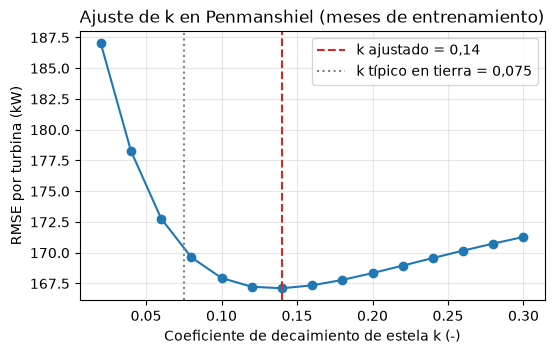

MAE turbina (kW)  RMSE turbina (kW)  \
pen (a) curva sin estelas             113.599998         185.600006   
kel (a) curva sin estelas             116.000000         196.500000   
pen (b) Jensen k=0,075                104.000000         170.000000   
    (b) Jensen k=0,14 ajustado        103.099998         168.199997   
kel (b) Jensen k=0,075                 84.199997         131.500000   
    (b) Jensen k=0,14 ajustado         91.800003         145.800003   

                                MAE parque (kW)  RMSE parque (kW)  
pen (a) curva sin estelas            977.799988       1539.900024  
kel (a) curva sin estelas            442.799988        687.700012  
pen (b) Jensen k=0,075               740.299988       1179.300049  
    (b) Jensen k=0,14 ajustado       757.299988       1212.199951  
kel (b) Jensen k=0,075               280.399994        416.799988  
    (b) Jensen k=0,14 ajustado       305.299988        460.899994

In [8]:
def fraccion_solape(d, r_estela, r_rotor=0.5):
    """Fracción del área del rotor (radio r_rotor) dentro del círculo de la estela, centros a distancia d."""
    d = np.abs(d)
    R, r = r_estela, r_rotor
    dentro = d <= (R - r)
    fuera = d >= (R + r)
    dd = np.maximum(d, 1e-9)
    a1 = np.arccos(np.clip((dd**2 + r**2 - R**2) / (2 * dd * r), -1, 1))
    a2 = np.arccos(np.clip((dd**2 + R**2 - r**2) / (2 * dd * R), -1, 1))
    lente = r**2 * a1 + R**2 * a2 - 0.5 * np.sqrt(np.clip((-dd + r + R) * (dd + r - R) * (dd - r + R) * (dd + r + R), 0, None))
    frac = lente / (np.pi * r**2)
    return np.where(dentro, 1.0, np.where(fuera, 0.0, frac))

def ct(U):
    return np.where(U <= 9, 0.8, 0.8 * (9 / np.maximum(U, 1e-3)) ** 3)

def jensen(f, k, filas=slice(None), desfases=(-6, -3, 0, 3, 6)):
    """Potencia predicha (T, N) por Jensen/Park, promediada sobre pequeños errores de dirección."""
    U, theta = f["U_inf"][filas], f["theta"][filas]
    a = (1 - np.sqrt(1 - ct(U)))[:, None, None]
    P = 0
    for d in desfases:
        x, y = geometria(f["xy"], theta + d, f["D"])
        xp = np.maximum(x, 0)                       # solo cuenta lo que está aguas abajo
        r_est = 0.5 + k * xp                         # radio de la estela en diámetros
        delta = np.where(x > 0, a * (0.5 / r_est) ** 2 * fraccion_solape(y, r_est), 0.0)
        U_ef = U[:, None] * (1 - np.sqrt((delta ** 2).sum(axis=1)))   # suma sobre las j que emiten estela
        P = P + f["curva"](U_ef)
    return (P / len(desfases)).astype(np.float32)

# ajuste de k en Penmanshiel (entrenamiento, submuestra para ir rápido)
rng = np.random.default_rng(SEMILLA)
idx_tr = rng.choice(np.nonzero(pen["tr"])[0], 6000, replace=False)
ks = np.round(np.arange(0.02, 0.31, 0.02), 3)
err = [np.mean((jensen(pen, k, idx_tr) - pen["P"][idx_tr]) ** 2) for k in ks]
k_aj = float(ks[int(np.argmin(err))])
JK_FIJO, JK_AJ = "(b) Jensen k=0,075", f"(b) Jensen k={k_aj:.2f} ajustado".replace(".", ",")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ks, np.sqrt(err), "o-")
ax.axvline(k_aj, color="tab:red", ls="--", label=f"k ajustado = {k_aj:.2f}".replace(".", ","))
ax.axvline(0.075, color="gray", ls=":", label="k típico en tierra = 0,075")
ax.set_xlabel("Coeficiente de decaimiento de estela k (-)")
ax.set_ylabel("RMSE por turbina (kW)")
ax.set_title("Ajuste de k en Penmanshiel (meses de entrenamiento)")
ax.legend()
plt.show()

for clave, f in (("pen", pen), ("kel", kel)):
    registrar(clave, JK_FIJO, f, jensen(f, 0.075), f["te"])
    registrar(clave, JK_AJ, f, jensen(f, k_aj), f["te"])
pd.DataFrame(resultados).T.round(1)


## 7. Preparar tensores para los modelos de aprendizaje

Ambos modelos de aprendizaje predicen el cociente $r_{t,i}$ y se entrenan con el error cuadrático medio sobre la potencia normalizada por la nominal:

$$\mathcal{L} = \frac{1}{TN}\sum_{t,i}\Big(\frac{r_{t,i}\,P_c(U_\infty(t)) - P_{t,i}}{P_{\text{nom}}}\Big)^2$$

**Rasgos de nodo** (iguales para todas las turbinas en un instante; lo que distingue a cada turbina son sus aristas): $U_\infty/15$, $\rho/1{,}225 - 1$, $\cos\bar\theta$, $\sin\bar\theta$.

**Rasgos de arista** $j \to i$: $x_{ji}/10$ e $y_{ji}/2$, solo donde existe la arista (máscara $M_{t,j,i}$).

**Una decisión con consecuencias:** la dirección absoluta ($\cos\bar\theta$, $\sin\bar\theta$) en el nodo permite aprender cosas que dependen del sitio ("en este parque, con viento del sureste, todo produce menos por el relieve"). Eso puede ayudar en el mismo parque, pero no tiene por qué ser cierto en otro. La geometría de las estelas ya está en las aristas, que sí son transferibles. Por eso entrenaremos también una variante de la GNN **sin** dirección absoluta en los nodos (solo geometría relativa).

Guardamos rasgos y máscara en tensores **densos** $N \times N$ (con $N \le 14$ son pequeños y fáciles de inspeccionar). Dentro de la GNN, en cambio, convertimos la máscara en una **lista de aristas** (índices emisor y receptor) y solo calculamos mensajes donde existe una arista: hay unas 30 aristas por instante en lugar de $14 \times 13 = 182$ pares, y el entrenamiento es unas 6 veces más rápido. Es la misma idea que usan las librerías de grafos.

In [9]:
def tensores(f, filas):
    """Rasgos de nodo X (B,N,4), aristas E (B,N,N,2), máscara M (B,N,N), P_c (B,), objetivo P (B,N)."""
    N = len(f["turbinas"])
    nodo = np.c_[f["U_inf"] / 15, f["rho"] / 1.225 - 1,
                 np.cos(np.deg2rad(f["theta"])), np.sin(np.deg2rad(f["theta"]))][filas]
    X = np.repeat(nodo[:, None, :], N, axis=1)
    E = np.stack([f["gx"][filas] / 10, f["gy"][filas] / 2], axis=-1) * f["M"][filas][..., None]
    a = lambda v: torch.tensor(np.asarray(v), dtype=torch.float32)
    return dict(X=a(X), E=a(E), M=a(f["M"][filas]), Pc=a(f["P_c"][filas] / f["P_nom"]),
                P=a(f["P"][filas] / f["P_nom"]))

datos_pen = {s: tensores(pen, pen[s]) for s in ("tr", "va", "te")}
datos_kel = tensores(kel, kel["te"])
for s, d in datos_pen.items():
    print(s, {k: tuple(v.shape) for k, v in d.items()})

tr {'X': (19149, 14, 4), 'E': (19149, 14, 14, 2), 'M': (19149, 14, 14), 'Pc': (19149,), 'P': (19149, 14)}
va {'X': (3984, 14, 4), 'E': (3984, 14, 14, 2), 'M': (3984, 14, 14), 'Pc': (3984,), 'P': (3984, 14)}
te {'X': (7372, 14, 4), 'E': (7372, 14, 14, 2), 'M': (7372, 14, 14), 'Pc': (7372,), 'P': (7372, 14)}



## 8. Método (c): MLP con el vector de todas las turbinas

Un perceptrón multicapa "plano" recibe un vector de longitud fija con las condiciones del parque y las coordenadas $(x_i, y_i)$ de **cada** turbina en el sistema del viento (respecto al centro del parque), concatenadas en un orden fijo, y devuelve un vector de $N$ cocientes:

$$[\,U_\infty, \rho, \cos\bar\theta, \sin\bar\theta, x_1, y_1, \dots, x_N, y_N\,] \;\xrightarrow{\text{MLP}}\; [\,r_1, \dots, r_N\,]$$

Esto funciona en el parque donde se entrena, y puede aprender cosas propias de cada turbina (por ejemplo, que la turbina 7 está en un valle). Pero la neurona de entrada 5 *es* la turbina 1 y la salida 3 *es* la turbina 3: con otro número de turbinas las dimensiones ni siquiera encajan, y aunque encajaran, cambiar el orden cambiaría la predicción. Por eso el MLP **no se puede aplicar a Kelmarsh**: en ese test solo comparamos (a), (b) y (d).

In [10]:
def entrada_mlp(f, d):
    """Concatena condiciones del parque y coordenadas de cada turbina en el sistema del viento."""
    th = np.deg2rad(f["theta"])
    filas = np.ones(len(th), bool) if d is None else d
    e = np.stack([-np.sin(th), -np.cos(th)], 1)[filas]
    p = f["xy"] / f["D"] - (f["xy"] / f["D"]).mean(0)
    xs = p @ e.T                                       # (N, B) coordenada aguas abajo
    ys = p @ np.stack([e[:, 1] * -1, e[:, 0]], 1).T    # (N, B) coordenada transversal
    base = np.c_[f["U_inf"] / 15, f["rho"] / 1.225 - 1, np.cos(th), np.sin(th)][filas]
    return torch.tensor(np.c_[base, xs.T / 10, ys.T / 10], dtype=torch.float32)

class MLPGranja(nn.Module):
    def __init__(self, n_entrada, n_turbinas, h=64):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(n_entrada, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(),
                                 nn.Linear(h, n_turbinas))
    def forward(self, z):
        return 1.3 * torch.sigmoid(self.red(z))       # cociente r entre 0 y 1,3

for s in ("tr", "va", "te"):
    datos_pen[s]["Z"] = entrada_mlp(pen, pen[s])
print("entrada del MLP:", tuple(datos_pen["tr"]["Z"].shape), "-> salida:", len(pen["turbinas"]), "cocientes")

entrada del MLP: (19149, 32) -> salida: 14 cocientes



## 9. Método (d): la GNN, paso de mensajes escrito a mano

Cada turbina $i$ tiene un estado oculto $\mathbf{h}_i \in \mathbb{R}^{H}$. Una **capa de paso de mensajes** hace tres cosas:

1. **Mensaje** de cada vecino aguas arriba $j$ a $i$, que depende del emisor, del receptor y de la geometría de la arista:
$$\mathbf{m}_{ji} = \phi_m\big(\mathbf{h}_j,\, \mathbf{h}_i,\, \mathbf{e}_{ji}\big)$$
2. **Agregación** de los mensajes que llegan a $i$. Por **suma** (cuenta cuántas estelas recibe):
$$\mathbf{a}_i = \sum_{j} M_{ji}\,\mathbf{m}_{ji}$$
o por **atención** (pesos que suman 1 y deciden qué vecino importa más):
$$\alpha_{ji} = \operatorname{softmax}_j\big(w^\top[\mathbf{h}_j, \mathbf{h}_i, \mathbf{e}_{ji}]\big), \qquad \mathbf{a}_i = \sum_j \alpha_{ji}\,\mathbf{m}_{ji}$$
3. **Actualización** del estado, con conexión residual:
$$\mathbf{h}_i \leftarrow \mathbf{h}_i + \phi_u(\mathbf{h}_i, \mathbf{a}_i)$$

$\phi_m$ y $\phi_u$ son MLP pequeños **compartidos por todas las turbinas y todas las aristas**. Esa es la clave: el número de parámetros no depende de $N$, y si se permutan las turbinas la salida se permuta igual (equivarianza). Con 2 capas, la información viaja dos saltos: la turbina 3 puede saber que la 2 está en la estela de la 1 (estela sobre estela).

Al final, una capa de salida común convierte $\mathbf{h}_i$ (estado oculto de la turbina $i$) en el cociente $r_i = 1{,}3\,\sigma(\psi(\mathbf{h}_i))$.



In [11]:
class CapaMensajes(nn.Module):
    def __init__(self, h, n_arista, atencion=False):
        super().__init__()
        self.phi_m = nn.Sequential(nn.Linear(2 * h + n_arista, h), nn.ReLU(), nn.Linear(h, h))
        self.phi_u = nn.Sequential(nn.Linear(2 * h, h), nn.ReLU(), nn.Linear(h, h))
        self.w_att = nn.Linear(2 * h + n_arista, 1) if atencion else None

    def forward(self, H, E, M):
        # H: (B, N, h) estados; E: (B, N, N, n_arista) rasgos de arista [b, j, i]; M: (B, N, N) máscara
        B, N, h = H.shape
        b, j, i = M.nonzero(as_tuple=True)               # lista de aristas existentes en el lote
        emisor, receptor = b * N + j, b * N + i          # índices de nodo "aplanados" (B*N nodos)
        Hf = H.reshape(B * N, h)
        z = torch.cat([Hf[emisor], Hf[receptor], E[b, j, i]], dim=-1)   # (n_aristas, 2h + n_arista)
        m = self.phi_m(z)                                # 1) un mensaje por arista: (n_aristas, h)
        if self.w_att is None:                           # 2) agregación por suma en el receptor
            a = torch.zeros_like(Hf).index_add_(0, receptor, m)
        else:                                            # 2') agregación por atención (softmax por receptor)
            s = self.w_att(z).squeeze(-1)
            w = torch.exp(s - s.max())
            den = torch.zeros(B * N).index_add_(0, receptor, w)
            alfa = w / (den[receptor] + 1e-12)
            a = torch.zeros_like(Hf).index_add_(0, receptor, alfa[:, None] * m)
        a = a.reshape(B, N, h)                           # nodos sin aristas de entrada reciben a = 0
        return H + self.phi_u(torch.cat([H, a], dim=-1))  # 3) actualización residual

class GNNGranja(nn.Module):
    def __init__(self, n_arista=2, h=32, capas=2, atencion=False, usar_direccion=True):
        super().__init__()
        self.usar_direccion = usar_direccion              # False: el nodo solo ve U_inf y rho
        self.codificador = nn.Linear(4 if usar_direccion else 2, h)
        self.capas = nn.ModuleList([CapaMensajes(h, n_arista, atencion) for _ in range(capas)])
        self.salida = nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))

    def forward(self, X, E, M):
        X = X if self.usar_direccion else X[..., :2]     # quita cos y sen de la dirección absoluta
        H = torch.relu(self.codificador(X))
        for capa in self.capas:
            H = capa(H, E, M)
        return 1.3 * torch.sigmoid(self.salida(H).squeeze(-1))   # cociente r: (B, N)

Antes de entrenar, sigamos **un instante** paso a paso para ver las formas de los tensores. Fíjate en que el mismo modelo, sin cambiar nada, acepta Penmanshiel ($N=14$) y Kelmarsh ($N=6$).

In [12]:
torch.manual_seed(SEMILLA)
gnn_demo = GNNGranja()
d1 = {k: v[:1] for k, v in datos_pen["tr"].items()}           # un solo instante
H = torch.relu(gnn_demo.codificador(d1["X"]))
capa = gnn_demo.capas[0]
B, N, h = H.shape
b, j, i = d1["M"].nonzero(as_tuple=True)
print("aristas (emisor -> receptor) en este instante:",
      [f"{pen['turbinas'][a][-2:]}->{pen['turbinas'][c][-2:]}" for a, c in zip(j.tolist(), i.tolist())])
z = torch.cat([H.reshape(-1, h)[b * N + j], H.reshape(-1, h)[b * N + i], d1["E"][b, j, i]], -1)
m = capa.phi_m(z)
a = torch.zeros(B * N, h).index_add_(0, b * N + i, m)
print("estados H:", tuple(H.shape), "| entrada de phi_m z:", tuple(z.shape), "| mensajes m:", tuple(m.shape),
      "| agregado a:", tuple(a.shape))
print("mensajes recibidos por turbina:", d1["M"][0].sum(0).int().tolist())
print("salida en Penmanshiel:", tuple(gnn_demo(d1["X"], d1["E"], d1["M"]).shape),
      "| salida en Kelmarsh:", tuple(gnn_demo(datos_kel["X"][:1], datos_kel["E"][:1], datos_kel["M"][:1]).shape))
print("parámetros GNN:", sum(p.numel() for p in gnn_demo.parameters()),
      "| parámetros MLP:", sum(p.numel() for p in MLPGranja(datos_pen["tr"]["Z"].shape[1], 14).parameters()))

aristas (emisor -> receptor) en este instante: ['01->04', '01->08', '02->05', '02->06', '02->09', '02->12', '02->13', '04->08', '05->08', '05->09', '05->12', '06->09', '06->10', '06->13', '07->10', '07->11', '07->14', '08->12', '09->12', '09->13', '10->13', '10->14', '11->14', '11->15']
estados H: (1, 14, 32) | entrada de phi_m z: (24, 66) | mensajes m: (24, 32) | agregado a: (14, 32)
mensajes recibidos por turbina: [0, 0, 1, 1, 1, 0, 3, 3, 2, 1, 4, 4, 3, 1]
salida en Penmanshiel: (1, 14) | salida en Kelmarsh: (1, 6)
parámetros GNN: 13921 | parámetros MLP: 7182



## 10. Entrenamiento con parada temprana

Una sola función de entrenamiento sirve para el MLP y la GNN: Adam, lotes de 256 instantes, y nos quedamos con los pesos de la época con menor error en validación (abril a junio 2019). El test temporal (julio a diciembre 2019) no se toca hasta el final.

Entrenamos cuatro modelos: el MLP, la GNN con agregación por suma, la GNN con atención y la GNN por suma sin dirección absoluta en los nodos ("solo geometría"). En CPU tarda unos pocos minutos en total.

(c) MLP                        entrenado en   5.7 s, mejor RMSE validación = 119.3 kW por turbina


(d) GNN suma                   entrenado en  47.9 s, mejor RMSE validación = 113.3 kW por turbina


(d) GNN atención               entrenado en  57.2 s, mejor RMSE validación = 113.3 kW por turbina


(d) GNN suma, solo geometría   entrenado en  47.5 s, mejor RMSE validación = 119.8 kW por turbina


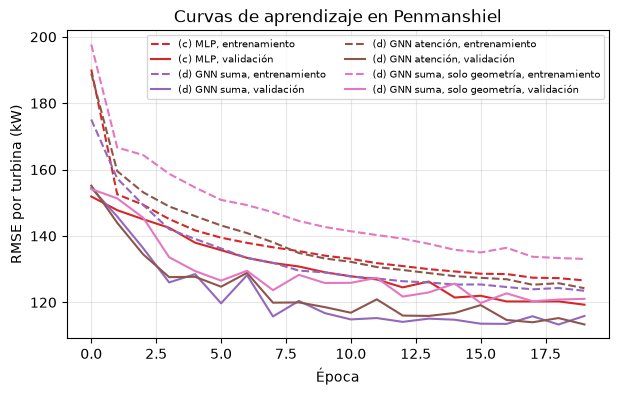

In [13]:
def predecir_r(modelo, d, tipo, lote=2048):
    modelo.eval()
    with torch.no_grad():
        n = d["P"].shape[0]
        if tipo == "mlp":
            return torch.cat([modelo(d["Z"][i:i + lote]) for i in range(0, n, lote)])
        return torch.cat([modelo(d["X"][i:i + lote], d["E"][i:i + lote], d["M"][i:i + lote])
                          for i in range(0, n, lote)])

def perdida(modelo, d, tipo):
    r = predecir_r(modelo, d, tipo)
    return float(((r * d["Pc"][:, None] - d["P"]) ** 2).mean())

def entrenar(modelo, tipo, epocas=20, lote=256, lr=2e-3):
    torch.manual_seed(SEMILLA)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    tr = datos_pen["tr"]
    n = tr["P"].shape[0]
    mejor, estado, hist = np.inf, None, []
    for ep in range(epocas):
        modelo.train()
        orden = torch.randperm(n)
        suma, lotes = 0.0, 0
        for i in range(0, n, lote):
            b = orden[i:i + lote]
            r = modelo(tr["Z"][b]) if tipo == "mlp" else modelo(tr["X"][b], tr["E"][b], tr["M"][b])
            loss = ((r * tr["Pc"][b, None] - tr["P"][b]) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            suma, lotes = suma + loss.item(), lotes + 1
        l_tr, l_va = suma / lotes, perdida(modelo, datos_pen["va"], tipo)   # entrenamiento: media de los lotes
        hist.append((l_tr, l_va))
        if l_va < mejor:
            mejor, estado = l_va, {k: v.clone() for k, v in modelo.state_dict().items()}
    modelo.load_state_dict(estado)
    return np.array(hist)

modelos, historias = {}, {}
for nombre, tipo, crear in [("(c) MLP", "mlp", lambda: MLPGranja(datos_pen["tr"]["Z"].shape[1], 14)),
                            ("(d) GNN suma", "gnn", lambda: GNNGranja(atencion=False)),
                            ("(d) GNN atención", "gnn", lambda: GNNGranja(atencion=True)),
                            ("(d) GNN suma, solo geometría", "gnn", lambda: GNNGranja(usar_direccion=False))]:
    t = time.time()
    torch.manual_seed(SEMILLA)
    modelos[nombre] = (crear(), tipo)
    historias[nombre] = entrenar(modelos[nombre][0], tipo)
    print(f"{nombre:30s} entrenado en {time.time() - t:5.1f} s, mejor RMSE validación = "
          f"{np.sqrt(historias[nombre][:, 1].min()) * pen['P_nom']:.1f} kW por turbina")

fig, ax = plt.subplots(figsize=(7, 4))
for (nombre, hst), color in zip(historias.items(), ["tab:red", "tab:purple", "tab:brown", "tab:pink"]):
    ax.plot(np.sqrt(hst[:, 0]) * pen["P_nom"], ls="--", color=color, label=f"{nombre}, entrenamiento")
    ax.plot(np.sqrt(hst[:, 1]) * pen["P_nom"], color=color, label=f"{nombre}, validación")
ax.set_xlabel("Época")
ax.set_ylabel("RMSE por turbina (kW)")
ax.set_title("Curvas de aprendizaje en Penmanshiel")
ax.legend(fontsize=7, ncol=2)
plt.show()


## 11. Test 1: meses no vistos en Penmanshiel

Convertimos los cocientes en potencia ($\hat P = r\,P_c(U_\infty)$) y comparamos los cuatro métodos en julio a diciembre de 2019. Añadimos una fila de **referencia no comparable**: la curva de potencia aplicada al viento de góndola **de cada turbina**. Ese viento ya lleva dentro la estela (la turbina en la estela mide menos viento), así que no es una predicción a partir de las condiciones del parque, pero sirve como "techo" de lo que se puede explicar con un anemómetro por turbina.

In [14]:
def potencia_modelo(f, d, nombre):
    modelo, tipo = modelos[nombre]
    r = predecir_r(modelo, d, tipo).numpy()
    return r * f["P_c"][f["te"], None]

for nombre in modelos:
    P_full = np.zeros_like(pen["P"])
    P_full[pen["te"]] = potencia_modelo(pen, datos_pen["te"], nombre)
    registrar("pen", nombre, pen, P_full, pen["te"])
    if nombre.startswith("(d)"):
        P_full = np.zeros_like(kel["P"])
        P_full[kel["te"]] = potencia_modelo(kel, datos_kel, nombre)
        registrar("kel", nombre, kel, P_full, kel["te"])

for clave, f in (("pen", pen), ("kel", kel)):
    resultados[(clave, "referencia: curva con viento de góndola propio")] = metricas(f, f["curva"](f["U"]), f["te"])

tabla = pd.DataFrame(resultados).T
tabla.index.names = ["test", "método"]
tabla_pen = tabla.loc["pen"].round(1)
tabla_pen["MAE turbina (% nominal)"] = (tabla_pen["MAE turbina (kW)"] / pen["P_nom"] * 100).round(2)
tabla_pen

,MAE turbina (kW),RMSE turbina (kW),MAE parque (kW),RMSE parque (kW),MAE turbina (% nominal)
método,,,,,
(a) curva sin estelas,113.599998,185.600006,977.799988,1539.900024,5.54
"(b) Jensen k=0,075",104.000000,170.000000,740.299988,1179.300049,5.07
"(b) Jensen k=0,14 ajustado",103.099998,168.199997,757.299988,1212.199951,5.03
(c) MLP,80.400002,126.300003,561.299988,860.000000,3.92
(d) GNN suma,77.099998,120.800003,510.399994,790.200012,3.76
(d) GNN atención,77.500000,121.699997,514.299988,795.299988,3.78
"(d) GNN suma, solo geometría",85.300003,133.399994,561.099976,857.900024,4.16
referencia: curva con viento de góndola propio,41.599998,67.199997,421.899994,655.000000,2.03


Errores por turbina en el test temporal. Las turbinas que más sufren estelas son donde se ve si un método entiende la geometría.

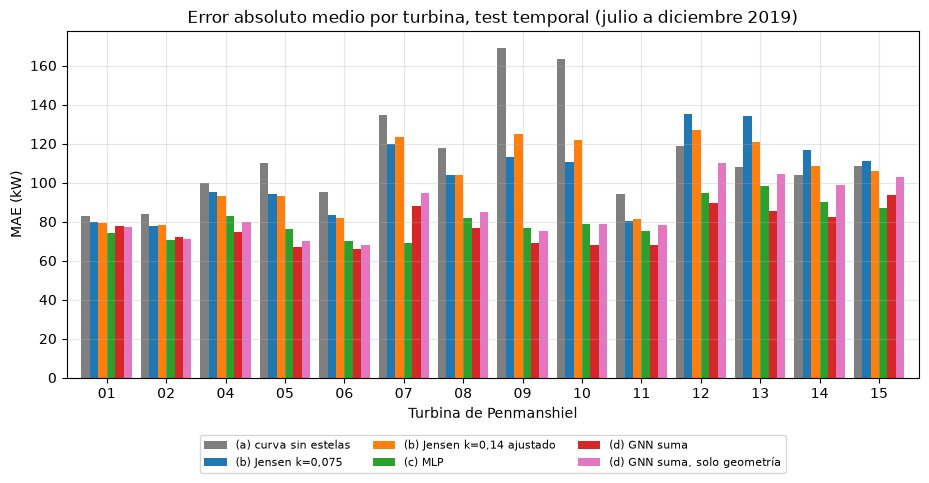

In [15]:
GNN_GEO = "(d) GNN suma, solo geometría"
metodos_pen = ["(a) curva sin estelas", JK_FIJO, JK_AJ, "(c) MLP", "(d) GNN suma", GNN_GEO]
metodos_kel = ["(a) curva sin estelas", JK_FIJO, JK_AJ, "(d) GNN suma", GNN_GEO]
COLORES = dict(zip(metodos_pen, ["tab:gray", "tab:blue", "tab:orange", "tab:green", "tab:red", "tab:pink"]))
mae_t = pd.DataFrame({m: np.abs(predicciones["pen"][m][pen["te"]] - pen["P"][pen["te"]]).mean(0) for m in metodos_pen},
                     index=[t.split("_")[1] for t in pen["turbinas"]])
ax = mae_t.plot.bar(figsize=(11, 4.5), width=0.85, rot=0, color=[COLORES[m] for m in metodos_pen])
ax.set_xlabel("Turbina de Penmanshiel")
ax.set_ylabel("MAE (kW)")
ax.set_title("Error absoluto medio por turbina, test temporal (julio a diciembre 2019)")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.show()


## 12. Test 2: otro parque que el modelo no ha visto (Kelmarsh)

Aplicamos **sin reentrenar** la GNN entrenada en Penmanshiel a Kelmarsh: 6 turbinas en vez de 14, otra disposición, otro diámetro (las distancias van en unidades de $D$, así que eso se absorbe). Lo único específico de Kelmarsh es su curva de potencia sin estelas, ajustada con 2018. El Jensen con $k$ ajustado usa el $k$ de Penmanshiel, que es justo la prueba de transferencia. El MLP no se puede aplicar (sección 8).

Aquí es donde se ve la diferencia entre las dos variantes de la GNN: la que usa la dirección absoluta puede haber aprendido rasgos de Penmanshiel que no existen en Kelmarsh; la de "solo geometría" no tiene forma de hacerlo.

In [16]:
tabla_kel = tabla.loc["kel"].round(1)
tabla_kel["MAE turbina (% nominal)"] = (tabla_kel["MAE turbina (kW)"] / kel["P_nom"] * 100).round(2)
tabla_kel

,MAE turbina (kW),RMSE turbina (kW),MAE parque (kW),RMSE parque (kW),MAE turbina (% nominal)
método,,,,,
(a) curva sin estelas,116.000000,196.500000,442.799988,687.700012,5.66
"(b) Jensen k=0,075",84.199997,131.500000,280.399994,416.799988,4.11
"(b) Jensen k=0,14 ajustado",91.800003,145.800003,305.299988,460.899994,4.48
(d) GNN suma,120.500000,193.399994,384.500000,581.000000,5.88
(d) GNN atención,125.000000,201.500000,397.600006,605.000000,6.10
"(d) GNN suma, solo geometría",110.000000,177.600006,355.100006,530.200012,5.37
referencia: curva con viento de góndola propio,44.700001,67.500000,166.699997,244.000000,2.18



## 13. Pérdida por estelas por sector de dirección

Las métricas globales mezclan muchas situaciones en las que no hay estela que predecir (viento alto, turbinas libres). La pérdida por sector aísla lo que nos interesa: **¿reproduce cada método cuánta energía pierde el parque por estelas según de dónde viene el viento?** (solo $5 \le U_\infty \le 11$ m/s, periodo de test). El método (a) no aparece en la figura porque por definición predice pérdida cero en todos los sectores; en la tabla su error es simplemente el tamaño medio de la pérdida medida.

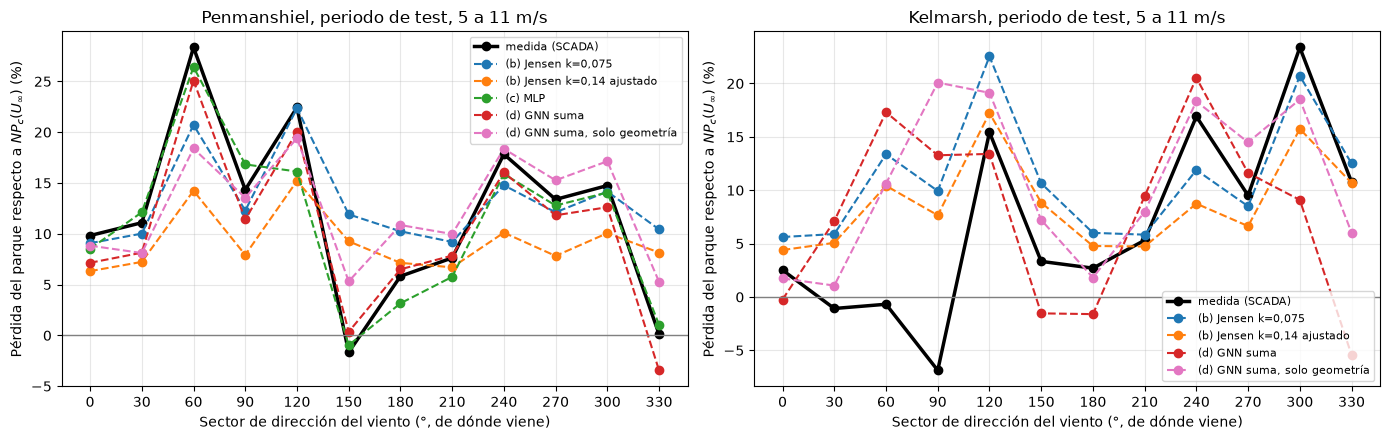

error medio absoluto por sector (puntos %)
pen (a) curva sin estelas                                              12.27
    (b) Jensen k=0,075                                                  3.86
    (b) Jensen k=0,14 ajustado                                          6.19
    (c) MLP                                                             1.87
    (d) GNN suma                                                        2.18
    (d) GNN suma, solo geometría                                        3.51
kel (a) curva sin estelas                                               8.21
    (b) Jensen k=0,075                                                  5.80
    (b) Jensen k=0,14 ajustado                                          5.20
    (d) GNN suma                                                        8.38
    (d) GNN suma, solo geometría                                        5.69

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (clave, f, metodos) in zip(axs, [("pen", pen, metodos_pen), ("kel", kel, metodos_kel)]):
    medida = perdida_por_sector(f, f["P"], f["te"])
    ax.plot(medida.index, medida.values, "k-o", lw=2.5, label="medida (SCADA)")
    for m in metodos[1:]:
        s = perdida_por_sector(f, predicciones[clave][m], f["te"])
        ax.plot(s.index, s.values, "o--", color=COLORES[m], label=m)
    ax.axhline(0, color="gray", lw=1)
    ax.set_xticks(SECTORES)
    ax.set_xlabel("Sector de dirección del viento (°, de dónde viene)")
    ax.set_ylabel("Pérdida del parque respecto a $N P_c(U_\\infty)$ (%)")
    ax.set_title(f"{f['nombre'].capitalize()}, periodo de test, 5 a 11 m/s")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

filas = {}
for clave, f, metodos in [("pen", pen, metodos_pen), ("kel", kel, metodos_kel)]:
    medida = perdida_por_sector(f, f["P"], f["te"])
    for m in metodos:
        filas[(clave, m)] = {"error medio absoluto por sector (puntos %)":
                             (perdida_por_sector(f, predicciones[clave][m], f["te"]) - medida).abs().mean()}
pd.DataFrame(filas).T.round(2)

**Una nota sobre la curva "medida".** Por construcción, la pérdida usa como referencia $N P_c(U_\infty)$, y $U_\infty$ se calcula con las turbinas libres. En terreno complejo las turbinas libres no son todas iguales (unas están más altas que otras), así que parte de la "pérdida" medida en algunos sectores es efecto del terreno y no de las estelas. Un valor negativo significa que el parque produjo más que $N$ veces la turbina libre media.


## 14. ¿Cuándo merece la pena una GNN y cuándo no?

Hasta aquí, el resultado honesto es incómodo para la GNN: en el mismo parque gana al MLP por poco (un 4 %) y en otro parque pierde contra Jensen, y la variante con dirección absoluta aprendió el sitio. ¿Significa eso que las GNN no sirven para estelas? No necesariamente. Con dos parques reales no podemos separar tres causas posibles:

1. **Falta de diversidad:** se entrenó con **un solo** layout. Una red que solo ha visto una geometría no tiene por qué aprender una regla que valga para otras.
2. **Física fácil:** quizá la física de estos parques se describe bien con Jensen y no hay mucho más que aprender.
3. **Ruido:** con un único viento de parque, la mayor parte del error no es de estelas (sección 22, punto 5), y eso tapa las diferencias entre modelos.

Para separarlas usamos un **banco de pruebas sintético con verdad conocida**: un simulador de granjas en el que nosotros decidimos el layout, la física de las estelas y el ruido. Así podemos preguntar cosas que con SCADA real no se pueden contestar:

| Experimento | Pregunta |
|---|---|
| 1. Layouts nuevos | Con física rica y muchos layouts de entrenamiento, ¿gana la GNN en granjas que nunca ha visto, incluso mayores? |
| 2. Número de layouts | ¿Cuántas geometrías distintas hacen falta para que la GNN generalice? ¿Reproduce el caso de Kelmarsh con un solo layout? |
| 3. Física sencilla | Si la verdad es casi un Jensen, ¿aporta algo la GNN? |
| 4. Ablaciones | ¿Qué partes de la GNN importan: el desplazamiento transversal, la referencia del viento, la agregación, el número de capas? |
| 5. Vuelta al caso real | ¿Mejora la GNN en Kelmarsh si se ajusta con unas semanas de datos locales? |

Todos los métodos se evalúan con **los mismos conjuntos de test**, los modelos aprendidos con **varias semillas**, y el presupuesto de ejecución de esta parte es de unos pocos minutos en CPU.


## 15. Un simulador de granjas con verdad conocida

**Layouts.** Generamos granjas de dos tipos, con distancias en diámetros de rotor $D$:

- **Malla alineada:** filas y columnas con espaciado entre 3 y 9 $D$ en cada eje, a veces al tresbolillo, girada un ángulo aleatorio y con un pequeño desorden (0,15 $D$).
- **Irregular:** posiciones al azar con una distancia mínima de 3 $D$ entre turbinas y un espaciado típico entre 4,5 y 8 $D$.

**Cada parque es un sitio.** Como en la realidad, cada layout tiene:

- un **viento dominante** propio: en los datos de entrenamiento la dirección sigue una distribución de von Mises ($\kappa = 1{,}5$, parámetro de concentración) alrededor de una dirección al azar, de modo que un parque ve unas geometrías mucho más que otras;
- un pequeño **efecto del terreno**: el viento de cada turbina se multiplica por $1 + 0{,}01\,(a_i\cos\theta + b_i\sin\theta)$, con $a_i, b_i$ propios de cada turbina y parque (unos ±1 % de viento, ±3 % de potencia). Es lo que un modelo puede "memorizar" de su parque y que no sirve en otro.

**Condiciones.** Cada muestra es un instante con viento libre $U_\infty$ entre 4 y 14 m/s, intensidad de turbulencia ambiente $I_0$ entre 4 % y 16 %. En el test, la dirección es **uniforme**. En entrenamiento, además del viento dominante, **quitamos el sector de 60° a 120°**: así el test contiene direcciones que ningún modelo ha visto, lo que importa sobre todo para el MLP de layout fijo.

**Física "verdadera"** (más rica que el Jensen de manual, y desconocida para los modelos):

- Déficit **gaussiano** tipo Bastankhah y Porté-Agel, con un ancho que crece con la distancia y con la turbulencia **local** de la turbina emisora:
$$\frac{\sigma}{D} = k^*(I_j)\,x + 0{,}2\sqrt{\beta_j}, \quad k^* = 0{,}38\,I_j + 0{,}004, \quad \beta_j = \frac{1}{2}\frac{1+\sqrt{1-C_{T,j}}}{\sqrt{1-C_{T,j}}}$$
$$\frac{\Delta U_{ji}}{U_j} = \Big(1-\sqrt{1-\tfrac{C_{T,j}}{8(\sigma/D)^2}}\Big)\exp\!\Big(-\frac{y_{ji}^2}{2(\sigma/D)^2}\Big)$$
- $C_T$ depende de la velocidad **local** $U_j$ de la turbina emisora (una turbina en estela empuja distinto), con una curva distinta de la que usa nuestro Jensen.
- **Turbulencia añadida** por las estelas (Crespo y Hernández): $I_j = \sqrt{I_0^2 + \sum_k (I^+_{kj})^2}$, de modo que una turbina en estela genera a su vez una estela que se recupera **más rápido**. Es un efecto de segundo orden que Jensen no tiene.
- Composición por suma de cuadrados: $U_i = U_\infty - \sqrt{\sum_j \Delta U_{ji}^2}$, resuelta por iteración (las estelas dependen de las velocidades aguas arriba).
- **Estela desviada:** el centro de la estela se desplaza lateralmente $(0{,}10 - 0{,}5\,I_0)\,x$ (por ejemplo por el giro del viento con la altura), más con poca turbulencia. Jensen supone estelas centradas.
- **Ruido:** variación local del viento del 1,5 % por turbina en cada instante y 15 kW de ruido de medida en la potencia.

La curva de potencia (2 MW, arranque 3 m/s, nominal 12 m/s) es conocida y común a todas las turbinas, igual que en la parte real usamos $P_c(U_\infty)$.

In [18]:
T_BANCO = time.time()   # para medir cuánto tarda esta segunda parte
P_NOM_S = 2000.0     # kW, turbina genérica del simulador
SECTOR_OCULTO = (60, 120)   # direcciones que no aparecen en entrenamiento

def curva_sint(U):
    """Curva de potencia genérica (kW): cúbica entre 3 y 12 m/s, nominal por encima."""
    U = np.asarray(U, dtype=np.float64)
    return (P_NOM_S * np.clip((U ** 3 - 27) / (12 ** 3 - 27), 0, 1)).astype(np.float32)

def ct_real(U):
    """C_T de la física 'verdadera', función de la velocidad local (distinta del ct() de Jensen)."""
    return np.clip(np.where(U <= 7.5, 0.82, 0.82 * (7.5 / np.maximum(U, 1e-3)) ** 2.6), 0.05, 0.82)

def layout_aleatorio(rng, N):
    """Un parque: posiciones (N, 2) en diámetros D, tipo, efecto del sitio y dirección dominante."""
    if rng.random() < 0.5:
        sx, sy = rng.uniform(3, 9, 2)
        c = max(2, int(np.ceil(np.sqrt(N * sy / sx))))
        r = int(np.ceil(N / c))
        I, J = np.meshgrid(np.arange(r), np.arange(c), indexing="ij")
        x = J * sx + (rng.random() < 0.3) * (I % 2) * sx / 2       # tresbolillo a veces
        p = np.c_[x.ravel(), (I * sy).ravel()][:N] + rng.normal(0, 0.15, (N, 2))
        tipo = "malla"
    else:
        s = rng.uniform(4.5, 8)
        lado = s * np.sqrt(N)
        p = np.zeros((0, 2))
        while len(p) < N:
            q = rng.uniform(0, lado, 2)
            if len(p) == 0 or np.min(np.hypot(*(p - q).T)) >= 3:
                p = np.vstack([p, q])
        tipo = "irregular"
    a = rng.uniform(0, 2 * np.pi)
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    p = (p - p.mean(0)) @ R.T
    return parque(p, tipo, rng)

def parque(p, tipo, rng):
    """Cada parque tiene su 'terreno' (coeficientes a_i, b_i por turbina) y su viento dominante."""
    return dict(xy=p.astype(np.float32), tipo=tipo, sitio=rng.normal(0, 1, (len(p), 2)) / np.sqrt(2),
                dominante=rng.uniform(0, 360))

def direcciones(rng, S, dominante):
    """Entrenamiento: alrededor del viento dominante del parque (von Mises, kappa = 1,5)."""
    return (dominante + np.rad2deg(rng.vonmises(0, 1.5, S))) % 360

def condiciones(rng, S, entrenamiento, dominante):
    U = rng.uniform(4, 14, S)
    TI = rng.uniform(0.04, 0.16, S)
    if not entrenamiento:                      # test: todas las direcciones por igual
        return U, TI, rng.uniform(0, 360, S)
    theta = direcciones(rng, S, dominante)
    a, b = SECTOR_OCULTO                       # entrenamiento: re-muestrea el sector oculto
    while ((theta >= a) & (theta < b)).any():
        m = (theta >= a) & (theta < b)
        theta[m] = direcciones(rng, m.sum(), dominante)
    return U, TI, theta

def fisica_rica(gx, gy, U, TI, pasadas=8):
    """Velocidad efectiva (S, N) con déficit gaussiano, C_T local, turbulencia añadida y estela desviada."""
    aguas_abajo = gx > 0.5
    xp = np.where(aguas_abajo, gx, 1.0)
    Uj = np.repeat(U[:, None], gx.shape[1], 1)
    Ij = np.repeat(TI[:, None], gx.shape[1], 1)
    desvio = (0.10 - 0.5 * TI)[:, None, None] * xp          # estela torcida: más con poca turbulencia
    for _ in range(pasadas):                                # iteración: cada pasada propaga un salto más
        C = ct_real(Uj)
        raiz = np.sqrt(1 - C)
        beta = 0.5 * (1 + raiz) / raiz
        sig = (0.38 * Ij + 0.004)[:, :, None] * xp + 0.2 * np.sqrt(beta)[:, :, None]   # (S, j, i)
        deficit = 1 - np.sqrt(np.clip(1 - C[:, :, None] / (8 * sig ** 2), 0, None))
        forma = np.exp(-(gy - desvio) ** 2 / (2 * sig ** 2)) * aguas_abajo
        dU = Uj[:, :, None] * deficit * forma
        a_ind = 0.5 * (1 - raiz)                             # inducción axial del emisor
        I_mas = 0.73 * a_ind[:, :, None] ** 0.8325 * TI[:, None, None] ** 0.0325 * xp ** -0.32 * forma
        Uj = U[:, None] - np.sqrt((dU ** 2).sum(1))
        Ij = np.sqrt(TI[:, None] ** 2 + (I_mas ** 2).sum(1))
    return Uj

def fisica_sencilla(gx, gy, U, TI, k=0.05):
    """Verdad 'casi Jensen': mismo modelo de cilindro con k = 0,05 y el ct() de manual."""
    a = (1 - np.sqrt(1 - ct(U)))[:, None, None]
    r_est = 0.5 + k * np.maximum(gx, 0)
    delta = np.where(gx > 0, a * (0.5 / r_est) ** 2 * fraccion_solape(gy, r_est), 0.0)
    return U[:, None] * (1 - np.sqrt((delta ** 2).sum(1)))

def granja_sintetica(rng, lay, S, entrenamiento, fisica):
    """S instantes de un parque: geometría del grafo, condiciones, verdad y observación con ruido."""
    xy = lay["xy"]
    U, TI, theta = condiciones(rng, S, entrenamiento, lay["dominante"])
    gx, gy = geometria(xy, theta, 1.0)            # misma función que en la parte real, con D = 1
    th = np.deg2rad(theta)[:, None]
    sitio = 1 + 0.01 * (lay["sitio"][:, 0] * np.cos(th) + lay["sitio"][:, 1] * np.sin(th))   # terreno: unos ±1 %
    U_ef = fisica(gx, gy, U, TI) * sitio
    ruido_u = 1 + 0.015 * rng.standard_normal(U_ef.shape)
    P_obs = curva_sint(U_ef * ruido_u) + 15 * rng.standard_normal(U_ef.shape)
    return dict(xy=xy, U=U, TI=TI, theta=theta, gx=gx, gy=gy,
                P=np.clip(P_obs, 0, P_NOM_S).astype(np.float32), P_verdad=curva_sint(U_ef))

def jensen_sint(g, k):
    """Jensen de la sección 6 aplicado a una granja sintética; k escalar o un valor por instante."""
    U = g["U"]
    k = np.broadcast_to(np.asarray(k, dtype=np.float64), U.shape)[:, None, None]
    a = (1 - np.sqrt(1 - ct(U)))[:, None, None]
    r_est = 0.5 + k * np.maximum(g["gx"], 0)
    delta = np.where(g["gx"] > 0, a * (0.5 / r_est) ** 2 * fraccion_solape(g["gy"], r_est), 0.0)
    return curva_sint(U[:, None] * (1 - np.sqrt((delta ** 2).sum(1))))

Un vistazo a la diferencia entre la física "verdadera" y Jensen para un par de turbinas a 5 $D$, con $U_\infty = 8$ m/s: el déficit gaussiano es más profundo en el centro, más suave en los bordes y su anchura depende de la turbulencia. Jensen da un escalón de anchura fija; su único parámetro $k$ no puede reproducir a la vez el centro y los bordes para todas las turbulencias. Además, la estela verdadera está **desplazada** hacia un lado, más con poca turbulencia. Eso es lo que llamamos un modelo **mal especificado**.

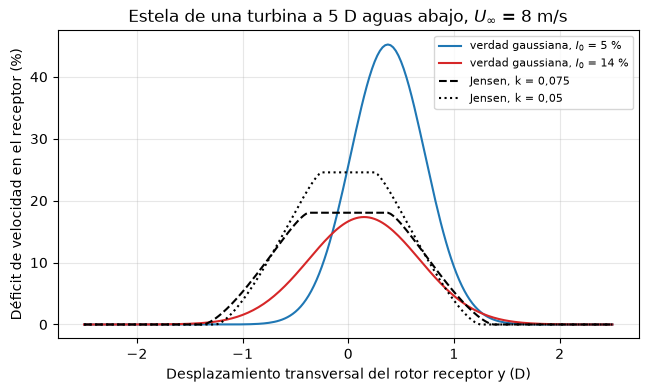

In [19]:
yy = np.linspace(-2.5, 2.5, 201).astype(np.float32)
fig, ax = plt.subplots(figsize=(7.5, 4))
for ti, color in [(0.05, "tab:blue"), (0.14, "tab:red")]:
    gx_p = np.zeros((1, 2, 2), np.float32); gy_p = np.zeros((1, 2, 2), np.float32)
    deficit = []
    for y0 in yy:
        gx_p[0, 0, 1], gy_p[0, 0, 1] = 5.0, y0
        deficit.append(1 - fisica_rica(gx_p, gy_p, np.array([8.0]), np.array([ti]))[0, 1] / 8)
    ax.plot(yy, np.array(deficit) * 100, color=color, label=f"verdad gaussiana, $I_0$ = {ti * 100:.0f} %")
for k_, ls in [(0.075, "--"), (0.05, ":")]:
    a_ = 1 - np.sqrt(1 - ct(np.array(8.0)))
    r_ = 0.5 + k_ * 5
    d_ = a_ * (0.5 / r_) ** 2 * fraccion_solape(yy, r_)
    ax.plot(yy, d_ * 100, "k", ls=ls, label=f"Jensen, k = {k_}".replace(".", ","))
ax.set_xlabel("Desplazamiento transversal del rotor receptor y (D)")
ax.set_ylabel("Déficit de velocidad en el receptor (%)")
ax.set_title("Estela de una turbina a 5 D aguas abajo, $U_\\infty$ = 8 m/s")
ax.legend(fontsize=8)
plt.show()

**Conjuntos de datos.** Generamos de una vez todas las granjas, con semillas fijas:

- **Reserva de entrenamiento:** 100 layouts de 8 a 30 turbinas. Cada experimento elige $L$ (número de layouts) de ellos y usa un **presupuesto fijo de 3.000 instantes**, repartidos entre los layouts elegidos (1 layout × 3.000 instantes, 5 × 600, 100 × 30...). Así, al comparar 1 frente a 100 layouts medimos el efecto de la **diversidad**, no de tener más datos. La validación (parada temprana, 600 instantes) son instantes nuevos **de los mismos layouts de entrenamiento**: es lo que tendría quien entrena con su(s) parque(s). Cada semilla elige otros layouts.
- **Test de layouts nuevos:** 40 layouts nunca vistos, de 8 a 60 turbinas (la mitad mayores que cualquiera de entrenamiento), 50 instantes cada uno y todas las direcciones.
- **Layout fijo A** (malla de 4 × 4 a 7 × 5 $D$): para el MLP, que solo funciona con un número y un orden de turbinas fijos. 3.000 instantes de entrenamiento y 1.000 de test.

Cada conjunto se genera dos veces, con la física rica y con la sencilla, **con los mismos layouts y las mismas condiciones**, para que la única diferencia sea la física.

simulación en 2.9 s | layouts de test: 40, turbinas de 8 a 60, 20 con más de 30 turbinas


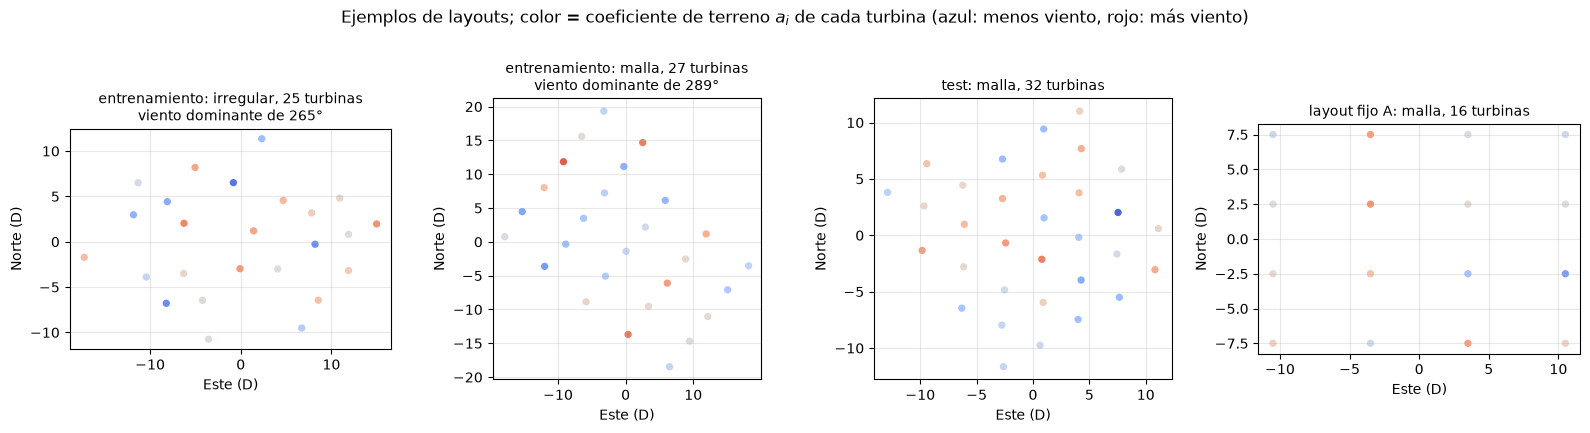

In [20]:
t_sim = time.time()
rng_lay = np.random.default_rng(100)
LAY_TR = [layout_aleatorio(rng_lay, int(n)) for n in rng_lay.integers(8, 31, 100)]
LAY_TE = [layout_aleatorio(rng_lay, int(n)) for n in np.r_[rng_lay.integers(8, 31, 20), rng_lay.integers(31, 61, 20)]]
I_, J_ = np.meshgrid(np.arange(4), np.arange(4), indexing="ij")
xy_A = np.c_[J_.ravel() * 7.0, I_.ravel() * 5.0]
LAY_A = parque(xy_A - xy_A.mean(0), "malla", rng_lay)
FISICAS = {"rica": fisica_rica, "sencilla": fisica_sencilla}
PRESUPUESTO_TR, PRESUPUESTO_VA = 3000, 600

def generar_test(fisica):
    """Test común a todos los métodos. La misma semilla en las dos físicas: mismos instantes."""
    rng = np.random.default_rng(7)
    return dict(test=[granja_sintetica(rng, lay, 50, False, fisica) for lay in LAY_TE],
                A_tr=granja_sintetica(rng, LAY_A, 3000, True, fisica),
                A_te=granja_sintetica(rng, LAY_A, 1000, False, fisica))

_cache_tr = {}
def conjunto_entrenamiento(fis, L, semilla):
    """L layouts de la reserva con 3.000 instantes en total y 600 de validación (de esos mismos layouts)."""
    clave = (fis, L, semilla)
    if clave not in _cache_tr:
        rng = np.random.default_rng(1000 * L + semilla)     # semilla distinta = otros layouts y otros instantes
        idx = rng.choice(len(LAY_TR), L, replace=False)
        tr = [granja_sintetica(rng, LAY_TR[l], PRESUPUESTO_TR // L, True, FISICAS[fis]) for l in idx]
        va = [granja_sintetica(rng, LAY_TR[l], max(PRESUPUESTO_VA // L, 5), True, FISICAS[fis]) for l in idx]
        _cache_tr[clave] = (tr, va)
    return _cache_tr[clave]

SIM = {fis: generar_test(f) for fis, f in FISICAS.items()}
n_te = np.array([len(g["xy"]) for g in SIM["rica"]["test"]])
print(f"simulación en {time.time() - t_sim:.1f} s | layouts de test: {len(n_te)}, turbinas de {n_te.min()} a {n_te.max()}, "
      f"{(n_te > 30).sum()} con más de 30 turbinas")

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, lay, titulo in zip(axs, [LAY_TR[0], LAY_TR[1], LAY_TE[-1], LAY_A],
                                  ["entrenamiento", "entrenamiento", "test", "layout fijo A"]):
    xy = lay["xy"]
    ax.scatter(xy[:, 0], xy[:, 1], s=18, c=lay["sitio"][:, 0], cmap="coolwarm", vmin=-2, vmax=2)
    ax.set_title(f"{titulo}: {lay['tipo']}, {len(xy)} turbinas" +
                 (f"\nviento dominante de {lay['dominante']:.0f}°" if titulo == "entrenamiento" else ""), fontsize=10)
    ax.set_xlabel("Este (D)")
    ax.set_ylabel("Norte (D)")
    ax.set_aspect("equal")
fig.suptitle("Ejemplos de layouts; color = coeficiente de terreno $a_i$ de cada turbina (azul: menos viento, rojo: más viento)", y=1.04)
plt.tight_layout()
plt.show()

**Tensores para el banco sintético.** Reutilizamos `GNNGranja` y `MLPGranja` sin cambiar ni una línea. Solo cambian los rasgos:

- Nodo: $U_\infty/15$, $I_0/0{,}1 - 1$ (en lugar de la densidad), $\cos\theta$, $\sin\theta$. Las GNN del banco usan `usar_direccion=False`, es decir, solo las dos primeras: ven la dirección únicamente a través de la geometría relativa de las aristas.
- Arista: $x_{ji}/10$, $y_{ji}/2$ con la misma máscara que antes ($0 < x \le 20$, $|y| \le 4$).
- Como las granjas tienen distinto número de turbinas, los lotes se **rellenan** hasta el máximo con nodos ficticios sin aristas, y una máscara de nodo $V$ los excluye de la pérdida.

`variante` permite construir las versiones de las ablaciones de la sección 19 con el mismo código.

In [21]:
def tensores_sint(grupo, variante="xy"):
    """Lista de granjas -> tensores rellenados (B, Nmax, ...) con máscara de nodo V."""
    Nmax = max(len(g["xy"]) for g in grupo)
    partes = {k: [] for k in ("X", "E", "M", "Pc", "P", "V")}
    for g in grupo:
        S, N = g["P"].shape
        nodo = np.c_[g["U"] / 15, g["TI"] / 0.1 - 1, np.cos(np.deg2rad(g["theta"])), np.sin(np.deg2rad(g["theta"]))]
        if variante == "absoluta":      # sin referencia del viento: vecinos por distancia y offsets este/norte
            dxa = g["xy"][None, :, 0] - g["xy"][:, None, 0]
            dya = g["xy"][None, :, 1] - g["xy"][:, None, 1]
            M = np.broadcast_to(((np.hypot(dxa, dya) <= 10) & ~np.eye(N, dtype=bool)), (S, N, N)).astype(np.float32)
            E = np.broadcast_to(np.stack([dxa / 10, dya / 10], -1), (S, N, N, 2)) * M[..., None]
        else:
            M = mascara_aristas(g["gx"], g["gy"])
            if variante == "distancia":  # solo la distancia, sin saber si la estela está centrada
                E = (np.hypot(g["gx"], g["gy"]) / 10)[..., None] * M[..., None]
            else:
                E = np.stack([g["gx"] / 10, g["gy"] / 2], -1) * M[..., None]
        pad = Nmax - N
        partes["X"].append(np.pad(np.repeat(nodo[:, None, :], N, 1), ((0, 0), (0, pad), (0, 0))))
        partes["E"].append(np.pad(E, ((0, 0), (0, pad), (0, pad), (0, 0))))
        partes["M"].append(np.pad(M, ((0, 0), (0, pad), (0, pad))))
        partes["Pc"].append(curva_sint(g["U"]) / P_NOM_S)
        partes["P"].append(np.pad(g["P"] / P_NOM_S, ((0, 0), (0, pad))))
        partes["V"].append(np.pad(np.ones((S, N)), ((0, 0), (0, pad))))
    return {k: torch.tensor(np.concatenate(v), dtype=torch.float32) for k, v in partes.items()}

def entrada_mlp_sint(g):
    """Vector fijo del MLP: condiciones + (x, y) de cada turbina en el sistema del viento (como en la sección 8)."""
    th = np.deg2rad(g["theta"])
    e = np.stack([-np.sin(th), -np.cos(th)], 1)
    xs, ys = g["xy"] @ e.T, g["xy"] @ np.stack([-e[:, 1], e[:, 0]], 1).T
    base = np.c_[g["U"] / 15, g["TI"] / 0.1 - 1, np.cos(th), np.sin(th)]
    return dict(Z=torch.tensor(np.c_[base, xs.T / 10, ys.T / 10], dtype=torch.float32),
                Pc=torch.tensor(curva_sint(g["U"]) / P_NOM_S), P=torch.tensor(g["P"] / P_NOM_S),
                V=torch.ones(g["P"].shape))

def entrenar_sint(modelo, tipo, tr, va, semilla, epocas=14, lote=128, lr=3e-3):
    """Como entrenar() de la sección 10, con máscara de nodo y conjuntos arbitrarios."""
    torch.manual_seed(semilla)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    adelante = (lambda d, b: modelo(d["Z"][b])) if tipo == "mlp" else (lambda d, b: modelo(d["X"][b], d["E"][b], d["M"][b]))
    def error(d, b):
        return ((((adelante(d, b) * d["Pc"][b, None] - d["P"][b]) ** 2) * d["V"][b]).sum() / d["V"][b].sum())
    n = tr["P"].shape[0]
    mejor, estado = np.inf, None
    for ep in range(epocas):
        modelo.train()
        orden = torch.randperm(n)
        for i in range(0, n, lote):
            loss = error(tr, orden[i:i + lote])
            opt.zero_grad()
            loss.backward()
            opt.step()
        modelo.eval()
        with torch.no_grad():
            l_va = float(error(va, torch.arange(va["P"].shape[0])))
        if l_va < mejor:
            mejor, estado = l_va, {k: v.clone() for k, v in modelo.state_dict().items()}
    modelo.load_state_dict(estado)
    return np.sqrt(mejor) * P_NOM_S        # RMSE de validación (kW)

def predecir_sint(modelo, grupo, variante="xy", tipo="gnn"):
    """Predicción (kW) para cada granja de la lista, sin relleno."""
    modelo.eval()
    salida = []
    with torch.no_grad():
        for g in grupo:
            if tipo == "mlp":
                d = entrada_mlp_sint(g)
                r = modelo(d["Z"])
            else:
                d = tensores_sint([g], variante)
                r = modelo(d["X"], d["E"], d["M"])
            salida.append((r * d["Pc"][:, None]).numpy() * P_NOM_S)
    return salida

def errores_sint(grupo, pred, filtro=None):
    """MAE por turbina (kW) y MAE del parque (% de la potencia instalada) sobre una lista de granjas."""
    e_t, e_p = [], []
    for g, p in zip(grupo, pred):
        sel = np.ones(len(g["U"]), bool) if filtro is None else filtro(g)
        e_t.append(np.abs(p[sel] - g["P"][sel]).ravel())
        e_p.append(np.abs(p[sel].sum(1) - g["P"][sel].sum(1)) / (len(g["xy"]) * P_NOM_S) * 100)
    return np.concatenate(e_t).mean(), np.concatenate(e_p).mean()

def en_sector_oculto(g):
    return (g["theta"] >= SECTOR_OCULTO[0]) & (g["theta"] < SECTOR_OCULTO[1])

**Entrenamiento en el banco sintético.** Misma receta para todas las GNN: Adam con tasa constante $6\cdot 10^{-3}$, lotes de 128 instantes, 20 épocas y parada temprana con la validación de los propios layouts. Un detalle práctico: inicializamos el sesgo de la capa de salida a 1,2, porque $1{,}3\,\sigma(1{,}2) \approx 1$. Así la red **empieza prediciendo "sin estelas"** y solo tiene que aprender las pérdidas, lo que acelera mucho el entrenamiento cuando hay pocas épocas. No cambia la arquitectura.

Los modelos entrenados se guardan en un diccionario para no repetir entrenamientos entre experimentos (por ejemplo, la GNN con 100 layouts del experimento 1 es la misma que el punto $L = 100$ del experimento 2).

In [22]:
import copy
EPOCAS_S, LR_S = 20, 6e-3

def nueva_gnn(semilla, usar_direccion=False, **kw):
    torch.manual_seed(semilla)
    m = GNNGranja(usar_direccion=usar_direccion, **kw)
    with torch.no_grad():
        m.salida[-1].bias.fill_(1.2)          # 1,3·σ(1,2) ≈ 1: al empezar predice "sin estelas"
    return m

GNN_SINT = {}
def gnn_sint(fis, L, semilla, variante="xy", **kw):
    """Entrena (o recupera) una GNN con L layouts de la física indicada y la evalúa en el test común."""
    clave = (fis, L, semilla, variante, tuple(sorted(kw.items())))
    if clave not in GNN_SINT:
        t = time.time()
        tr, va = conjunto_entrenamiento(fis, L, semilla)
        kw = dict(kw)
        m = nueva_gnn(semilla, usar_direccion=kw.pop("usar_direccion", variante == "absoluta"),
                      n_arista=1 if variante == "distancia" else 2, **kw)
        entrenar_sint(m, "gnn", tensores_sint(tr, variante), tensores_sint(va, variante), semilla,
                      epocas=EPOCAS_S, lr=LR_S)
        GNN_SINT[clave] = dict(modelo=m, segundos=time.time() - t,
                               propios=errores_sint(va, predecir_sint(m, va, variante))[0],
                               pred=predecir_sint(m, SIM[fis]["test"], variante),
                               pred_A=predecir_sint(m, [SIM[fis]["A_te"]], variante))
    return GNN_SINT[clave]

def ajustar_jensen(grupo, por_ti):
    """k único (rejilla 0,02 a 0,20) o k = c·I0 (rejilla de c), por mínimo error cuadrático; 10 instantes por layout."""
    sub = [dict(g, U=g["U"][:10], TI=g["TI"][:10], gx=g["gx"][:10], gy=g["gy"][:10], P=g["P"][:10]) for g in grupo]
    rejilla = np.round(np.arange(0.3, 1.61, 0.1), 2) if por_ti else np.round(np.arange(0.02, 0.201, 0.01), 3)
    err = [np.mean(np.concatenate([((jensen_sint(g, c * g["TI"] if por_ti else c) - g["P"]) ** 2).ravel() for g in sub]))
           for c in rejilla]
    return float(rejilla[int(np.argmin(err))])

def predicciones_clasicas(grupo, k_aj, c_ti):
    return {"(a) curva sin estelas": [np.repeat(curva_sint(g["U"])[:, None], len(g["xy"]), 1) for g in grupo],
            "(b) Jensen k=0,075": [jensen_sint(g, 0.075) for g in grupo],
            "(b) Jensen k ajustado": [jensen_sint(g, k_aj) for g in grupo],
            "(b) Jensen k=c·I0 ajustado": [jensen_sint(g, c_ti * g["TI"]) for g in grupo]}

CLASICOS = {}
for fis in FISICAS:
    tr100, _ = conjunto_entrenamiento(fis, 100, 0)
    k_aj, c_ti = ajustar_jensen(tr100, False), ajustar_jensen(tr100, True)
    CLASICOS[fis] = dict(k=k_aj, c=c_ti, test=predicciones_clasicas(SIM[fis]["test"], k_aj, c_ti),
                         A=predicciones_clasicas([SIM[fis]["A_te"]], k_aj, c_ti))
    print(f"física {fis:8s}: k ajustado = {k_aj:.2f}, k = {c_ti:.1f}·I0 ajustado (100 layouts de entrenamiento)")

def fila_metricas(grupo, pred):
    grandes = [i for i, g in enumerate(grupo) if len(g["xy"]) > 30]
    t, p = errores_sint(grupo, pred)
    return {"MAE turbina (kW)": t, "MAE parque (% instalada)": p,
            "MAE turbina, sector no visto (kW)": errores_sint(grupo, pred, en_sector_oculto)[0],
            "MAE turbina, granjas de 31 a 60 (kW)": errores_sint([grupo[i] for i in grandes], [pred[i] for i in grandes])[0]}

def mejor_clasico(fis):
    """Mejor método clásico EN EL TEST (elección optimista a favor de los clásicos)."""
    te = SIM[fis]["test"]
    return min((errores_sint(te, p)[0], m) for m, p in CLASICOS[fis]["test"].items())

física rica    : k ajustado = 0.09, k = 1.0·I0 ajustado (100 layouts de entrenamiento)


física sencilla: k ajustado = 0.05, k = 0.5·I0 ajustado (100 layouts de entrenamiento)



## 16. Experimento 1: granjas y direcciones nunca vistas, con física rica

Comparamos en los 40 layouts de test (8 a 60 turbinas, todas las direcciones):

- (a) curva sin estelas, (b) Jensen con $k = 0{,}075$, con $k$ ajustado y con $k = c\,I_0$ ajustado (le damos a Jensen la turbulencia, que es lo que haría un ingeniero). Los $k$ se ajustan con los mismos datos de entrenamiento que la GNN.
- (d) GNN entrenada con 100 layouts de 8 a 30 turbinas, dos semillas.
- (c) El MLP **no es aplicable**: su entrada tiene $4 + 2N$ números en un orden fijo; con otro $N$ la primera capa ni siquiera tiene el tamaño adecuado, y con el mismo $N$ pero otro layout la neurona "turbina 5" significaría otra cosa. Lo evaluamos más abajo en su terreno, el layout fijo A.
- Referencia no alcanzable: la **verdad sin ruido**. Su error es el ruido que hemos añadido: ningún método puede bajar de ahí.

In [23]:
t_exp = time.time()
tabla_nuevos = {m: fila_metricas(SIM["rica"]["test"], p) for m, p in CLASICOS["rica"]["test"].items()}
tabla_nuevos["(c) MLP"] = {c: np.nan for c in tabla_nuevos["(a) curva sin estelas"]}   # no aplicable
filas_gnn = [fila_metricas(SIM["rica"]["test"], gnn_sint("rica", 100, s)["pred"]) for s in (0, 1)]
tabla_nuevos["(d) GNN, 100 layouts (media de 2 semillas)"] = pd.DataFrame(filas_gnn).mean().to_dict()
tabla_nuevos["referencia: verdad sin ruido"] = fila_metricas(SIM["rica"]["test"], [g["P_verdad"] for g in SIM["rica"]["test"]])
tabla_nuevos = pd.DataFrame(tabla_nuevos).T
tabla_nuevos["desv. entre semillas (kW)"] = np.nan
tabla_nuevos.loc["(d) GNN, 100 layouts (media de 2 semillas)", "desv. entre semillas (kW)"] = \
    pd.DataFrame(filas_gnn)["MAE turbina (kW)"].std()
print(f"experimento 1 en {time.time() - t_exp:.0f} s; MLP: no aplicable a layouts nuevos (tamaño de entrada fijo)")
tabla_nuevos.round(2)

experimento 1 en 30 s; MLP: no aplicable a layouts nuevos (tamaño de entrada fijo)


,MAE turbina (kW),MAE parque (% instalada),"MAE turbina, sector no visto (kW)","MAE turbina, granjas de 31 a 60 (kW)",desv. entre semillas (kW)
(a) curva sin estelas,79.96,3.08,86.02,84.30,NaN
"(b) Jensen k=0,075",48.17,1.23,49.43,49.18,NaN
(b) Jensen k ajustado,46.45,1.11,47.31,47.40,NaN
(b) Jensen k=c·I0 ajustado,45.81,0.97,47.60,46.40,NaN
(c) MLP,NaN,NaN,NaN,NaN,NaN
"(d) GNN, 100 layouts (media de 2 semillas)",43.61,0.79,43.06,44.92,0.93
referencia: verdad sin ruido,25.66,0.32,25.02,25.83,NaN


Error por layout de test frente a su número de turbinas. La línea vertical marca el tamaño máximo visto en entrenamiento: a la derecha, la GNN predice granjas hasta dos veces mayores que cualquiera de las que conoce.

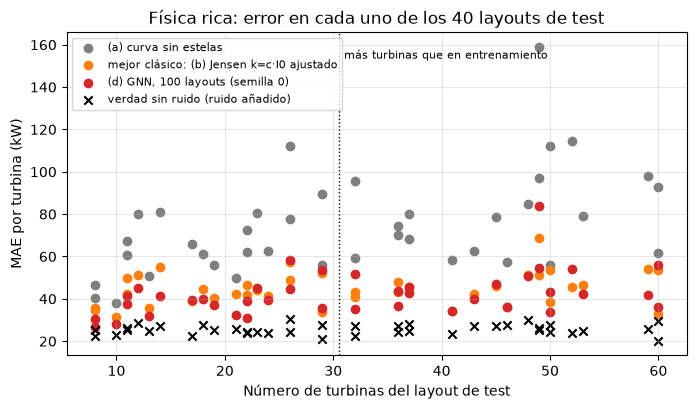

In [24]:
te = SIM["rica"]["test"]
_, m_clas = mejor_clasico("rica")
mae_lay = lambda pred: [np.abs(p - g["P"]).mean() for g, p in zip(te, pred)]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(n_te, mae_lay(CLASICOS["rica"]["test"]["(a) curva sin estelas"]), color="tab:gray", label="(a) curva sin estelas")
ax.scatter(n_te, mae_lay(CLASICOS["rica"]["test"][m_clas]), color="tab:orange", label=f"mejor clásico: {m_clas}")
ax.scatter(n_te, mae_lay(gnn_sint("rica", 100, 0)["pred"]), color="tab:red", label="(d) GNN, 100 layouts (semilla 0)")
ax.scatter(n_te, mae_lay([g["P_verdad"] for g in te]), color="k", marker="x", label="verdad sin ruido (ruido añadido)")
ax.axvline(30.5, color="k", ls=":", lw=1)
ax.text(31, ax.get_ylim()[1] * 0.95, "más turbinas que en entrenamiento", fontsize=8, va="top")
ax.set_xlabel("Número de turbinas del layout de test")
ax.set_ylabel("MAE por turbina (kW)")
ax.set_title("Física rica: error en cada uno de los 40 layouts de test")
ax.legend(fontsize=8)
plt.show()

**En su terreno: el layout fijo A.** Ahora sí podemos entrenar el MLP (3.000 instantes de A, tres semillas, 40 épocas porque es barato). La GNN de 100 layouts **nunca ha visto A**. El test de A incluye el sector de 60° a 120°, que ninguno de los dos ha visto en entrenamiento.

In [25]:
t_a = time.time()
A_tr, A_te = SIM["rica"]["A_tr"], SIM["rica"]["A_te"]
corte = int(0.8 * len(A_tr["U"]))
parte = lambda g, sl: dict(g, **{k: g[k][sl] for k in ("U", "TI", "theta", "gx", "gy", "P", "P_verdad")})
d_A_tr, d_A_va = entrada_mlp_sint(parte(A_tr, slice(0, corte))), entrada_mlp_sint(parte(A_tr, slice(corte, None)))

def fila_A(pred):
    t, p = errores_sint([A_te], pred)
    return {"MAE turbina (kW)": t, "MAE parque (% instalada)": p,
            "MAE turbina, sector no visto (kW)": errores_sint([A_te], pred, en_sector_oculto)[0]}

tabla_A = {m: fila_A(p) for m, p in CLASICOS["rica"]["A"].items()}
filas_mlp = []
for s in (0, 1, 2):
    torch.manual_seed(s)
    mlp = MLPGranja(d_A_tr["Z"].shape[1], 16)
    with torch.no_grad():
        mlp.red[-1].bias.fill_(1.2)
    entrenar_sint(mlp, "mlp", d_A_tr, d_A_va, s, epocas=40, lr=3e-3)
    filas_mlp.append(fila_A(predecir_sint(mlp, [A_te], tipo="mlp")))
tabla_A["(c) MLP entrenado en A (media de 3 semillas)"] = pd.DataFrame(filas_mlp).mean().to_dict()
tabla_A["(d) GNN, 100 layouts, sin ver A (media de 2 semillas)"] = \
    pd.DataFrame([fila_A(gnn_sint("rica", 100, s)["pred_A"]) for s in (0, 1)]).mean().to_dict()
tabla_A["referencia: verdad sin ruido"] = fila_A([A_te["P_verdad"]])
print(f"layout A en {time.time() - t_a:.0f} s")
pd.DataFrame(tabla_A).T.round(2)

layout A en 5 s


,MAE turbina (kW),MAE parque (% instalada),"MAE turbina, sector no visto (kW)"
(a) curva sin estelas,58.26,2.17,55.04
"(b) Jensen k=0,075",43.12,1.28,40.52
(b) Jensen k ajustado,41.24,1.20,38.43
(b) Jensen k=c·I0 ajustado,42.15,1.26,38.97
(c) MLP entrenado en A (media de 3 semillas),46.38,1.41,59.69
"(d) GNN, 100 layouts, sin ver A (media de 2 semillas)",33.91,0.70,31.84
referencia: verdad sin ruido,25.85,0.39,25.23


**Lectura del experimento 1.**

- **En layouts nuevos gana la GNN, sobre todo en el total del parque.** Por turbina, 43,6 kW frente a 45,8 kW del mejor Jensen ($k = c\,I_0$): solo un 5 % menos, porque gran parte del error por turbina es ruido (la verdad sin ruido ya tiene 25,7 kW) y efecto del terreno, que nadie puede predecir en un parque nuevo. En el **total del parque**, donde ese ruido se compensa, la diferencia es clara: 0,79 % frente a 0,97 % de la potencia instalada (un 19 % menos).
- **Generaliza en tamaño y en dirección.** En granjas de 31 a 60 turbinas (más grandes que cualquiera de entrenamiento) mantiene la ventaja (44,9 frente a 46,4 kW) y en el sector de 60° a 120°, que nunca vio, también (43,1 frente a 47,3 kW).
- **Layout fijo A.** La GNN que **no ha visto A** (33,9 kW) gana al Jensen ajustado (41,2 kW) y al MLP entrenado **en A** (46,4 kW). El MLP se hunde en el sector no visto (59,7 kW, peor que no modelar estelas): aprende una tabla "dirección → pérdidas" de su parque y no sabe interpolar a direcciones nuevas. La GNN, en cambio, solo ve geometría relativa, y una dirección nueva en A es una geometría parecida a otras que ya vio en otros parques.
- Dos semillas de la GNN difieren en menos de 1 kW: la ventaja no es casualidad de una inicialización.


## 17. Experimento 2: ¿cuántos layouts hacen falta?

Mismo presupuesto de 3.000 instantes, repartido entre $L = 1, 2, 5, 20$ o $100$ layouts, dos semillas (cada semilla elige otros layouts). Para cada modelo medimos dos errores:

- **en sus propios layouts** (instantes nuevos de los parques de entrenamiento): lo que vería quien solo valida en su parque;
- **en layouts nuevos** (el test común de 40 layouts).

Este experimento es la versión controlada de lo que pasó con Kelmarsh: con $L = 1$ la GNN se entrena con un único parque, igual que nuestra GNN real se entrenó solo con Penmanshiel. Con un solo parque, la red ve sobre todo las geometrías de su viento dominante y un terreno concreto, igual que en un parque real.

10 modelos en 102 s (incluye los ya entrenados) | k de Jensen ajustado con un solo layout: 0.20 (con 100 layouts: 0.09)


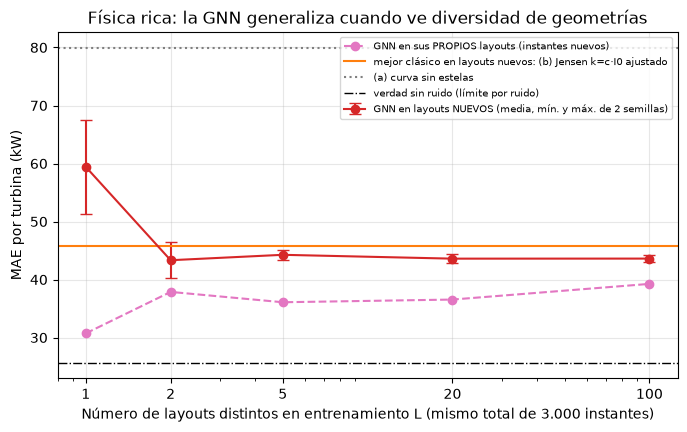

,"MAE turbina, propios layouts (kW)","MAE turbina, layouts nuevos (kW)","MAE parque, layouts nuevos (% instalada)"
L,,,
1,30.73,59.42,1.31
2,37.87,43.33,0.81
5,36.09,44.27,0.84
20,36.55,43.61,0.83
100,39.25,43.61,0.79


In [26]:
t_c = time.time()
LS = [1, 2, 5, 20, 100]
filas = []
for L in LS:
    for s in (0, 1):
        r = gnn_sint("rica", L, s)
        t_, p_ = errores_sint(SIM["rica"]["test"], r["pred"])
        filas.append(dict(L=L, semilla=s, propios=r["propios"], nuevos=t_, parque=p_, segundos=r["segundos"]))
curva_L = pd.DataFrame(filas)
mae_clas_rica, nombre_clas_rica = mejor_clasico("rica")
tr1, _ = conjunto_entrenamiento("rica", 1, 0)
print(f"{len(filas)} modelos en {time.time() - t_c:.0f} s (incluye los ya entrenados) | "
      f"k de Jensen ajustado con un solo layout: {ajustar_jensen(tr1, False):.2f} "
      f"(con 100 layouts: {CLASICOS['rica']['k']:.2f})")

med = curva_L.groupby("L")[["propios", "nuevos", "parque"]].agg(["mean", "min", "max"])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(LS, med["nuevos", "mean"], yerr=[med["nuevos", "mean"] - med["nuevos", "min"], med["nuevos", "max"] - med["nuevos", "mean"]],
            fmt="o-", color="tab:red", capsize=4, label="GNN en layouts NUEVOS (media, mín. y máx. de 2 semillas)")
ax.plot(LS, med["propios", "mean"], "o--", color="tab:pink", label="GNN en sus PROPIOS layouts (instantes nuevos)")
ax.axhline(mae_clas_rica, color="tab:orange", label=f"mejor clásico en layouts nuevos: {nombre_clas_rica}")
ax.axhline(errores_sint(SIM["rica"]["test"], CLASICOS["rica"]["test"]["(a) curva sin estelas"])[0], color="tab:gray", ls=":",
           label="(a) curva sin estelas")
ax.axhline(tabla_nuevos.loc["referencia: verdad sin ruido", "MAE turbina (kW)"], color="k", ls="-.", lw=1,
           label="verdad sin ruido (límite por ruido)")
ax.set_xscale("log")
ax.set_xticks(LS)
ax.set_xticklabels(LS)
ax.set_xlabel("Número de layouts distintos en entrenamiento L (mismo total de 3.000 instantes)")
ax.set_ylabel("MAE por turbina (kW)")
ax.set_title("Física rica: la GNN generaliza cuando ve diversidad de geometrías")
ax.legend(fontsize=7.5)
plt.show()
curva_L.groupby("L")[["propios", "nuevos", "parque"]].mean().round(2).rename(columns={
    "propios": "MAE turbina, propios layouts (kW)", "nuevos": "MAE turbina, layouts nuevos (kW)",
    "parque": "MAE parque, layouts nuevos (% instalada)"})

**Lectura del experimento 2: este es el punto central.**

- **Con un solo layout la GNN no generaliza:** 30,7 kW en su propio parque (el mejor número de toda la tabla) y 59,4 kW en parques nuevos, un 30 % **peor** que Jensen. Es exactamente lo que pasó en Kelmarsh: un error de validación excelente en el parque de entrenamiento no dice nada sobre otro parque. La red ha aprendido el terreno de su parque y las geometrías de su viento dominante.
- **Con variedad de layouts sí generaliza:** a partir de 2 layouts la GNN ya está por debajo de Jensen (43 a 44 kW). En este simulador la mejora se satura pronto, porque cada parque visto desde todas las direcciones ya aporta muchas geometrías relativas distintas; con física más variada (otras turbinas, estabilidad, terreno complejo) harían falta más.
- El hueco entre la curva rosa y la roja es la **memorización del sitio**: se cierra al aumentar $L$ (30,7 frente a 59,4 kW con $L = 1$; 39,3 frente a 43,6 kW con $L = 100$).
- Ojo con Jensen también: ajustado con un solo layout, su $k$ sale 0,20 en vez de 0,09. Un parámetro ajustado en un parque absorbe lo que es propio de ese parque, la misma conclusión que con el $k$ de Penmanshiel en la sección 12.


## 18. Experimento 3: si la física es sencilla y bien conocida

Repetimos el banco con la **física sencilla**: la verdad es un Jensen con $k = 0{,}05$ (más el mismo ruido). Mismos layouts, mismas condiciones, mismos tests. Ahora el modelo clásico está **bien especificado**: con un solo parámetro ajustado puede reproducir la verdad. Entrenamos la GNN con 1 y 100 layouts y dos semillas.

In [27]:
t_s = time.time()
tabla_sencilla = {m: fila_metricas(SIM["sencilla"]["test"], p) for m, p in CLASICOS["sencilla"]["test"].items()}
filas_s = []
for L in (1, 100):
    for s in (0, 1):
        r = gnn_sint("sencilla", L, s)
        t_, p_ = errores_sint(SIM["sencilla"]["test"], r["pred"])
        filas_s.append(dict(L=L, semilla=s, propios=r["propios"], nuevos=t_, parque=p_))
        if L in (1, 100):
            tabla_sencilla.setdefault(f"(d) GNN, {L} layout{'s' if L > 1 else ''} (media de 2 semillas)", []).append(
                fila_metricas(SIM["sencilla"]["test"], r["pred"]))
for m in [k for k in tabla_sencilla if k.startswith("(d)")]:
    tabla_sencilla[m] = pd.DataFrame(tabla_sencilla[m]).mean().to_dict()
tabla_sencilla["referencia: verdad sin ruido"] = fila_metricas(SIM["sencilla"]["test"], [g["P_verdad"] for g in SIM["sencilla"]["test"]])
curva_L_s = pd.DataFrame(filas_s)
print(f"física sencilla en {time.time() - t_s:.0f} s; k ajustado = {CLASICOS['sencilla']['k']:.2f} (verdad: 0,05)")
pd.DataFrame(tabla_sencilla).T.round(2)

física sencilla en 48 s; k ajustado = 0.05 (verdad: 0,05)


,MAE turbina (kW),MAE parque (% instalada),"MAE turbina, sector no visto (kW)","MAE turbina, granjas de 31 a 60 (kW)"
(a) curva sin estelas,106.26,4.30,118.53,113.04
"(b) Jensen k=0,075",37.85,0.92,39.36,38.72
(b) Jensen k ajustado,27.23,0.33,26.32,27.38
(b) Jensen k=c·I0 ajustado,35.16,0.72,36.79,35.77
"(d) GNN, 1 layout (media de 2 semillas)",55.38,1.14,54.78,58.56
"(d) GNN, 100 layouts (media de 2 semillas)",42.87,0.80,42.76,44.62
referencia: verdad sin ruido,25.29,0.31,24.42,25.45


**Lectura del experimento 3: aquí la GNN no aporta.** Con la física sencilla, Jensen con $k$ ajustado (27,2 kW por turbina, 0,33 % en el parque) prácticamente alcanza la verdad sin ruido (25,3 kW, 0,31 %): recupera $k = 0{,}05$ exacto con un solo parámetro. La GNN con 100 layouts se queda en 42,9 kW (0,80 %), y con un layout en 55,4 kW. Con el mismo presupuesto de datos y entrenamiento, una red de 14.000 parámetros no puede competir con el modelo correcto de un parámetro; con muchos más datos se acercaría, pero nunca lo superaría, porque no hay nada más que aprender.

**Regla práctica:** si un modelo físico sencillo bien ajustado ya explica los datos hasta el nivel del ruido, la GNN solo añade coste y riesgo. La GNN tiene sentido cuando el modelo físico está mal especificado de una forma que se puede aprender de los datos.


## 19. Experimento 4: ablaciones, ¿qué partes de la GNN importan?

Con la física rica y 100 layouts (semilla 0) cambiamos una sola cosa cada vez:

| Variante | Qué cambia |
|---|---|
| base | suma, arista $(x, y)$ en el sistema del viento, 2 capas |
| solo distancia | la arista solo lleva $\sqrt{x^2+y^2}$: sabe que hay un vecino aguas arriba, no si la estela le da de lleno o de refilón |
| sin referencia del viento | vecinos por distancia ($\le 10\,D$, en todas las direcciones) con desplazamientos este/norte, y la dirección del viento en el nodo; la red tiene que aprender a girar la geometría |
| atención | agregación con pesos softmax en vez de suma |
| 1 capa / 3 capas | alcance del paso de mensajes: 1, 2 o 3 saltos |

Para ver el **alcance**, separamos el error por la **profundidad** de cada turbina en la cadena de estelas: 0 = libre, 1 = detrás de una turbina libre, 2 o más = estela sobre estela (definida con un cono estrecho, $0 < x \le 15$, $|y| \le 1$).

In [28]:
def profundidad(g, x_max=15.0, y_max=1.0):
    """Profundidad de cada turbina (S, N) en la cadena de estelas: longitud del camino más largo aguas arriba."""
    A = (g["gx"] > 0) & (g["gx"] <= x_max) & (np.abs(g["gy"]) <= y_max)
    p = np.zeros(g["P"].shape)
    for _ in range(12):
        p = (A * (p[:, :, None] + 1)).max(1)
    return p

def mae_por_profundidad(grupo, pred):
    e = np.concatenate([np.abs(p - g["P"]).ravel() for g, p in zip(grupo, pred)])
    d = np.concatenate([profundidad(g).ravel() for g in grupo])
    return {f"MAE prof. {n} (kW)": e[sel].mean() for n, sel in [("0", d == 0), ("1", d == 1), ("≥2", d >= 2)]}

t_ab = time.time()
VARIANTES = {"base (suma, x e y, 2 capas)": dict(),
             "solo distancia": dict(variante="distancia"),
             "sin referencia del viento": dict(variante="absoluta"),
             "atención": dict(atencion=True),
             "1 capa": dict(capas=1),
             "3 capas": dict(capas=3)}
te = SIM["rica"]["test"]
tabla_abl = {}
for nombre, kw in VARIANTES.items():
    r = gnn_sint("rica", 100, 0, **kw)
    tabla_abl[nombre] = {**dict(zip(["MAE turbina (kW)", "MAE parque (% instalada)"], errores_sint(te, r["pred"]))),
                         **mae_por_profundidad(te, r["pred"]), "entrenamiento (s)": r["segundos"]}
tabla_abl[f"mejor clásico: {nombre_clas_rica}"] = {**dict(zip(["MAE turbina (kW)", "MAE parque (% instalada)"],
                                                              errores_sint(te, CLASICOS["rica"]["test"][nombre_clas_rica]))),
                                                   **mae_por_profundidad(te, CLASICOS["rica"]["test"][nombre_clas_rica])}
tabla_abl = pd.DataFrame(tabla_abl).T
d_all = np.concatenate([profundidad(g).ravel() for g in te])
print(f"ablaciones en {time.time() - t_ab:.0f} s | turbinas de test por profundidad: "
      f"0: {np.mean(d_all == 0):.0%}, 1: {np.mean(d_all == 1):.0%}, 2 o más: {np.mean(d_all >= 2):.0%} | "
      f"diferencia entre semillas de la base: "
      f"{abs(errores_sint(te, gnn_sint('rica', 100, 0)['pred'])[0] - errores_sint(te, gnn_sint('rica', 100, 1)['pred'])[0]):.1f} kW")
tabla_abl.round(2)

ablaciones en 84 s | turbinas de test por profundidad: 0: 56%, 1: 22%, 2 o más: 22% | diferencia entre semillas de la base: 1.3 kW


,MAE turbina (kW),MAE parque (% instalada),MAE prof. 0 (kW),MAE prof. 1 (kW),MAE prof. ≥2 (kW),entrenamiento (s)
"base (suma, x e y, 2 capas)",44.27,0.75,33.45,57.87,58.49,13.41
solo distancia,62.87,1.51,47.78,80.18,84.30,12.84
sin referencia del viento,68.24,1.77,52.74,83.76,92.45,24.21
atención,44.75,0.84,34.99,55.90,58.66,15.54
1 capa,50.63,1.03,37.40,66.03,69.18,7.85
3 capas,41.12,0.73,32.60,49.60,54.51,18.78
mejor clásico: (b) Jensen k=c·I0 ajustado,45.81,0.97,32.46,61.45,64.44,NaN


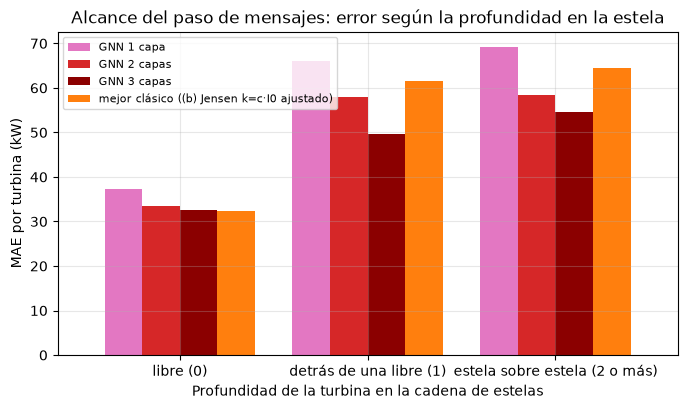

In [29]:
cols = ["MAE prof. 0 (kW)", "MAE prof. 1 (kW)", "MAE prof. ≥2 (kW)"]
sel = ["1 capa", "base (suma, x e y, 2 capas)", "3 capas", f"mejor clásico: {nombre_clas_rica}"]
ax = tabla_abl.loc[sel, cols].T.plot.bar(figsize=(8, 4.2), rot=0, width=0.8,
                                         color=["tab:pink", "tab:red", "darkred", "tab:orange"])
ax.set_xticklabels(["libre (0)", "detrás de una libre (1)", "estela sobre estela (2 o más)"])
ax.set_xlabel("Profundidad de la turbina en la cadena de estelas")
ax.set_ylabel("MAE por turbina (kW)")
ax.set_title("Alcance del paso de mensajes: error según la profundidad en la estela")
ax.legend(["GNN 1 capa", "GNN 2 capas", "GNN 3 capas", f"mejor clásico ({nombre_clas_rica})"], fontsize=8)
plt.show()

**Lectura del experimento 4.**

- **La geometría en el sistema del viento es lo que más importa.** Sin desplazamiento transversal ("solo distancia") el error sube de 44,3 a 62,9 kW; sin referencia del viento (offsets este/norte y la dirección en el nodo) sube a 68,2 kW, peor que Jensen. La red tendría que aprender a girar la geometría, y con estos datos no lo consigue. Elegir bien los rasgos de arista es más importante que la arquitectura.
- **Suma o atención da igual aquí** (44,3 frente a 44,8 kW), como en Penmanshiel.
- **El número de capas sí importa para las estelas encadenadas.** En turbinas con profundidad 2 o más (el 22 % de las del test): 69,2 kW con 1 capa (peor que Jensen, 64,4 kW), 58,5 kW con 2 y 54,5 kW con 3. Con una capa, una turbina sabe quién tiene delante pero no si ese vecino está a su vez en una estela (y por tanto empuja menos y deja una estela distinta). La tercera capa mejora un poco más (41,1 kW en total, la mejor variante), con un 40 % más de tiempo de entrenamiento.
- Estas ablaciones son de una sola semilla; la diferencia entre dos semillas de la versión base es de 1,3 kW, así que las diferencias de menos de 2 kW (suma frente a atención) no son significativas. Las de 6 kW o más sí.


## 20. Experimento 5: vuelta al caso real, Kelmarsh con unas semanas de datos locales

El experimento 2 explica por qué falló la transferencia a Kelmarsh en la sección 12: una GNN entrenada con un solo layout aprende ese layout. No tenemos 100 parques reales, pero sí podemos probar la solución práctica más común: **ajuste fino** (*fine-tuning*). Partimos de la GNN "solo geometría" entrenada en Penmanshiel y seguimos entrenándola con poca tasa de aprendizaje ($5\cdot 10^{-4}$, 20 épocas) usando solo las **últimas 2 semanas, 1 mes o 3 meses de 2018** de Kelmarsh (el 20 % final de cada ventana es validación). Comparamos, **con los mismos datos y el mismo test (todo 2019)**, con:

- Jensen con $k$ ajustado en esa misma ventana (rejilla de la sección 6);
- la misma GNN entrenada **desde cero** solo con la ventana ($3\cdot 10^{-3}$), para separar el valor del preentrenamiento.

Recuerda que la curva de potencia de Kelmarsh se ajustó con todo 2018 (sección 5): eso no cambia aquí.

In [30]:
t_ft = time.time()
VENTANAS = {"2 semanas": "2018-12-17", "1 mes": "2018-12-01", "3 meses": "2018-10-01"}
P_te_kel = lambda r: r * kel["P_c"][kel["te"], None]
filas_ft = []
for ventana, desde in VENTANAS.items():
    filas_v = np.nonzero(kel["cal"] & (kel["tiempo"] >= desde))[0]
    corte = filas_v[int(0.8 * len(filas_v))]
    d_tr = tensores(kel, filas_v[filas_v < corte])
    d_va = tensores(kel, filas_v[filas_v >= corte])
    for d in (d_tr, d_va):
        d["V"] = torch.ones(d["P"].shape)
    err = [np.mean((jensen(kel, k, filas_v) - kel["P"][filas_v]) ** 2) for k in ks]
    k_v = float(ks[int(np.argmin(err))])
    P_full = np.zeros_like(kel["P"])
    P_full[kel["te"]] = jensen(kel, k_v, kel["te"])
    m_ = metricas(kel, P_full, kel["te"])
    filas_ft.append(dict(ventana=ventana, instantes=len(filas_v), metodo=f"Jensen k ajustado en la ventana",
                         semilla=0, k=k_v, mae=m_["MAE turbina (kW)"], parque=m_["MAE parque (kW)"]))
    for s in (0, 1):
        for metodo, crear, lr in [("GNN preentrenada + ajuste fino", lambda: copy.deepcopy(modelos[GNN_GEO][0]), 5e-4),
                                  ("GNN desde cero", lambda: nueva_gnn(s), 3e-3)]:
            m = crear()
            entrenar_sint(m, "gnn", d_tr, d_va, s, epocas=20, lr=lr)
            P_full[kel["te"]] = P_te_kel(predecir_r(m, datos_kel, "gnn").numpy())
            m_ = metricas(kel, P_full, kel["te"])
            filas_ft.append(dict(ventana=ventana, instantes=len(filas_v), metodo=metodo, semilla=s, k=np.nan,
                                 mae=m_["MAE turbina (kW)"], parque=m_["MAE parque (kW)"]))
ft = pd.DataFrame(filas_ft)
print(f"ajuste fino en {time.time() - t_ft:.0f} s | k de Jensen por ventana: "
      + ", ".join(f"{v}: {k:.2f}" for v, k in ft.dropna(subset=["k"])[["ventana", "k"]].values))
ref_kel = {"Jensen k=0,075 (sin datos locales)": tabla.loc[("kel", JK_FIJO), "MAE turbina (kW)"],
           "GNN solo geometría sin ajuste": tabla.loc[("kel", GNN_GEO), "MAE turbina (kW)"]}
tabla_ft = ft.groupby(["ventana", "metodo"], sort=False)[["instantes", "mae", "parque"]].mean().round(1)
tabla_ft.columns = ["instantes de la ventana", "MAE turbina 2019 (kW)", "MAE parque 2019 (kW)"]
tabla_ft

ajuste fino en 38 s | k de Jensen por ventana: 2 semanas: 0.02, 1 mes: 0.04, 3 meses: 0.04


instantes de la ventana  \
ventana   metodo                                                     
2 semanas Jensen k ajustado en la ventana                    699.0   
          GNN preentrenada + ajuste fino                     699.0   
          GNN desde cero                                     699.0   
1 mes     Jensen k ajustado en la ventana                   1400.0   
          GNN preentrenada + ajuste fino                    1400.0   
          GNN desde cero                                    1400.0   
3 meses   Jensen k ajustado en la ventana                   3697.0   
          GNN preentrenada + ajuste fino                    3697.0   
          GNN desde cero                                    3697.0   

                                           MAE turbina 2019 (kW)  \
ventana   metodo                                                   
2 semanas Jensen k ajustado en la ventana              83.000000   
          GNN preentrenada + ajuste fino               85.699997   
          GNN desde cero                              101.000000   
1 mes     Jensen k ajustado en la ventana              82.300003   
          GNN preentrenada + ajuste fino               80.900002   
          GNN desde cero                               92.000000   
3 meses   Jensen k ajustado en la ventana              82.300003   
          GNN preentrenada + ajuste fino               77.300003   
          GNN desde cero                               84.099998   

                                           MAE parque 2019 (kW)  
ventana   metodo                                                 
2 semanas Jensen k ajustado en la ventana            280.899994  
          GNN preentrenada + ajuste fino             283.399994  
          GNN desde cero                             318.100006  
1 mes     Jensen k ajustado en la ventana            276.700012  
          GNN preentrenada + ajuste fino             268.700012  
          GNN desde cero                             291.299988  
3 meses   Jensen k ajustado en la ventana            276.700012  
          GNN preentrenada + ajuste fino             250.399994  
          GNN desde cero                             270.299988

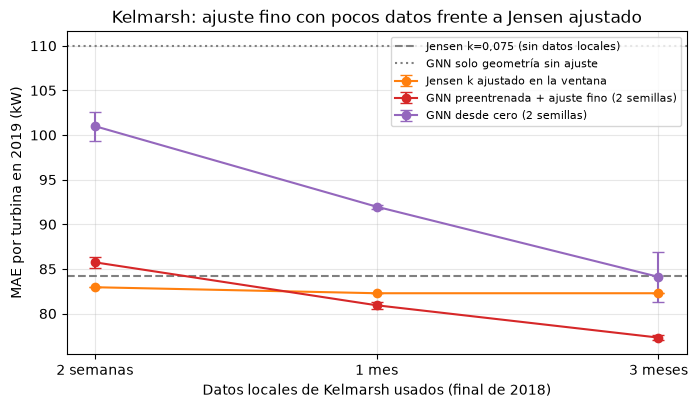

In [31]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x_v = np.arange(len(VENTANAS))
for metodo, color in [("Jensen k ajustado en la ventana", "tab:orange"), ("GNN preentrenada + ajuste fino", "tab:red"),
                      ("GNN desde cero", "tab:purple")]:
    g = ft[ft.metodo == metodo].groupby("ventana", sort=False)["mae"]
    ax.errorbar(x_v, g.mean().values, yerr=[g.mean().values - g.min().values, g.max().values - g.mean().values],
                fmt="o-", capsize=4, color=color, label=metodo + (" (2 semillas)" if "GNN" in metodo else ""))
for (nombre, v), ls in zip(ref_kel.items(), ["--", ":"]):
    ax.axhline(v, color="gray", ls=ls, label=nombre)
ax.set_xticks(x_v)
ax.set_xticklabels(list(VENTANAS))
ax.set_xlabel("Datos locales de Kelmarsh usados (final de 2018)")
ax.set_ylabel("MAE por turbina en 2019 (kW)")
ax.set_title("Kelmarsh: ajuste fino con pocos datos frente a Jensen ajustado")
ax.legend(fontsize=8)
plt.show()

**Lectura del experimento 5 (datos reales).**

- **Con 2 semanas de datos locales gana Jensen ajustado** (83,0 kW frente a 85,7 kW del ajuste fino). Con tan pocos datos, un parámetro es más fiable que miles.
- **Con 1 mes empatan** (82,3 frente a 80,9 kW) y **con 3 meses gana el ajuste fino** (77,3 frente a 82,3 kW por turbina, un 6 % menos; 250 frente a 277 kW en el total del parque, un 10 % menos). Es la primera vez en el cuaderno que una GNN gana en Kelmarsh.
- **El preentrenamiento en Penmanshiel ayuda:** la misma GNN entrenada desde cero con esos datos es peor en las tres ventanas (101, 92 y 84 kW). Lo que se aprendió en Penmanshiel no transfería tal cual (sección 12), pero es un buen punto de partida.
- Por qué Jensen apenas mejora con más datos: tiene un solo parámetro ($k$ sale 0,02 a 0,04, muy distinto del 0,075 de manual) y su error está dominado por lo que no modela. Esto es un solo parque de destino y dos semillas: indica una tendencia, no una garantía.


## 21. Mapa de decisión: cuándo usar una GNN y cuándo no

La figura resume los experimentos con un solo número: el **error relativo de la GNN frente al mejor método clásico** (MAE por turbina de la GNN dividido entre el del mejor clásico, menos 1). Negativo = gana la GNN. En el banco sintético, el "mejor clásico" se elige mirando el test, lo que favorece a los clásicos.

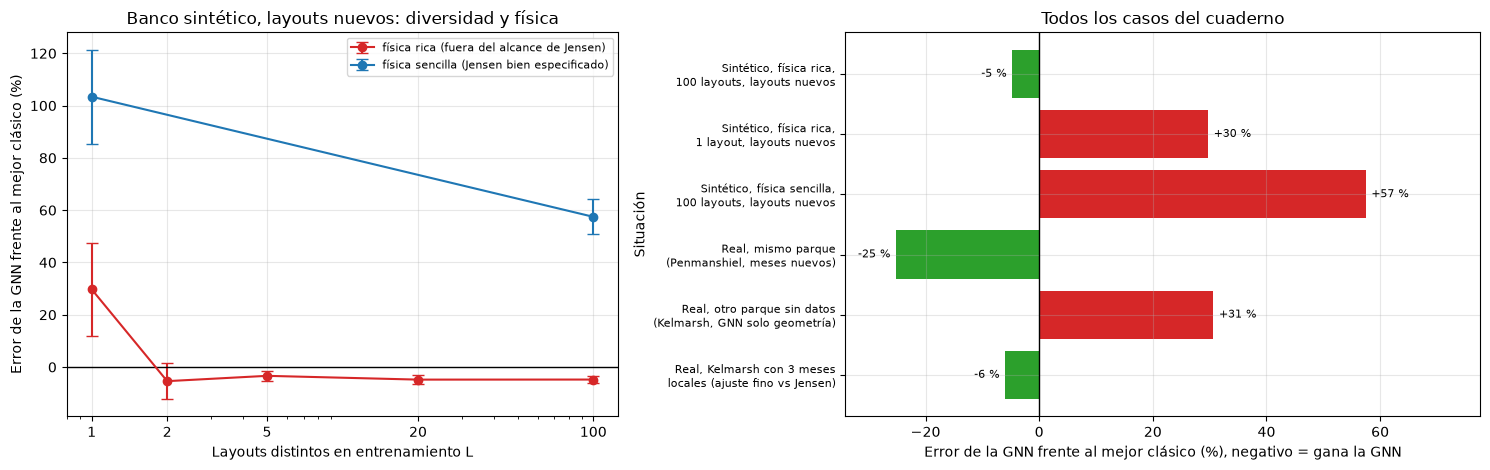

In [32]:
def relativo(mae_gnn, mae_clas):
    return (np.asarray(mae_gnn) / mae_clas - 1) * 100

mae_clas_sen, nombre_clas_sen = mejor_clasico("sencilla")
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax = axs[0]
for datos_c, mae_c, color, etiqueta in [(curva_L, mae_clas_rica, "tab:red", "física rica (fuera del alcance de Jensen)"),
                                        (curva_L_s, mae_clas_sen, "tab:blue", "física sencilla (Jensen bien especificado)")]:
    g = datos_c.groupby("L")["nuevos"]
    ax.errorbar(g.mean().index, relativo(g.mean(), mae_c),
                yerr=[relativo(g.mean(), mae_c) - relativo(g.min(), mae_c), relativo(g.max(), mae_c) - relativo(g.mean(), mae_c)],
                fmt="o-", capsize=4, color=color, label=etiqueta)
ax.axhline(0, color="k", lw=1)
ax.set_xscale("log")
ax.set_xticks(LS)
ax.set_xticklabels(LS)
ax.set_xlabel("Layouts distintos en entrenamiento L")
ax.set_ylabel("Error de la GNN frente al mejor clásico (%)")
ax.set_title("Banco sintético, layouts nuevos: diversidad y física")
ax.legend(fontsize=8)

mae_pen = lambda m: tabla.loc[("pen", m), "MAE turbina (kW)"]
mae_kel = lambda m: tabla.loc[("kel", m), "MAE turbina (kW)"]
ft3 = ft[ft.ventana == "3 meses"].groupby("metodo")["mae"].mean()
casos = {
    "Sintético, física rica,\n100 layouts, layouts nuevos": relativo(curva_L[curva_L.L == 100].nuevos.mean(), mae_clas_rica),
    "Sintético, física rica,\n1 layout, layouts nuevos": relativo(curva_L[curva_L.L == 1].nuevos.mean(), mae_clas_rica),
    "Sintético, física sencilla,\n100 layouts, layouts nuevos": relativo(curva_L_s[curva_L_s.L == 100].nuevos.mean(), mae_clas_sen),
    "Real, mismo parque\n(Penmanshiel, meses nuevos)": relativo(mae_pen("(d) GNN suma"), min(mae_pen(JK_FIJO), mae_pen(JK_AJ))),
    "Real, otro parque sin datos\n(Kelmarsh, GNN solo geometría)": relativo(mae_kel(GNN_GEO), min(mae_kel(JK_FIJO), mae_kel(JK_AJ))),
    "Real, Kelmarsh con 3 meses\nlocales (ajuste fino vs Jensen)": relativo(ft3["GNN preentrenada + ajuste fino"],
                                                                   ft3["Jensen k ajustado en la ventana"]),
}
ax = axs[1]
v = np.array(list(casos.values()), dtype=float)
ax.barh(list(casos), v, color=np.where(v < 0, "tab:green", "tab:red"))
for i, x in enumerate(v):
    ax.text(x + (1 if x >= 0 else -1), i, f"{x:+.0f} %", va="center", ha="left" if x >= 0 else "right", fontsize=8)
ax.axvline(0, color="k", lw=1)
ax.invert_yaxis()
ax.set_xlim(min(v.min() * 1.35, -10), max(v.max() * 1.35, 10))
ax.set_xlabel("Error de la GNN frente al mejor clásico (%), negativo = gana la GNN")
ax.set_ylabel("Situación")
ax.set_title("Todos los casos del cuaderno")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [33]:
f1 = lambda x: f"{x:.1f}".replace(".", ",")
g100, g1 = curva_L[curva_L.L == 100], curva_L[curva_L.L == 1]
s100 = curva_L_s[curva_L_s.L == 100]
mapa = pd.DataFrame([
    ("Hay que predecir layouts nuevos y se entrena con muchos layouts distintos, física compleja",
     "GNN",
     f"Sintético rico: GNN {f1(g100.nuevos.mean())} kW frente a {f1(mae_clas_rica)} kW del mejor clásico; también en granjas de 31 a 60 turbinas"),
    ("Un solo parque de entrenamiento y se quiere usar en otro parque",
     "No: Jensen u otro modelo físico",
     f"Sintético con 1 layout: {f1(g1.nuevos.mean())} kW en layouts nuevos ({f1(g1.propios.mean())} kW en el suyo). Real: Kelmarsh {f1(mae_kel(GNN_GEO))} kW frente a {f1(mae_kel(JK_FIJO))} kW de Jensen"),
    ("Un solo parque y se predice ese mismo parque",
     "MLP o GNN casi igual; la GNN no es imprescindible",
     f"Penmanshiel: GNN {f1(mae_pen('(d) GNN suma'))} kW, MLP {f1(mae_pen('(c) MLP'))} kW"),
    ("Física sencilla y bien conocida (el modelo clásico está bien especificado)",
     "No: modelo clásico ajustado",
     f"Sintético sencillo: Jensen ajustado {f1(mae_clas_sen)} kW, GNN con 100 layouts {f1(s100.nuevos.mean())} kW"),
    ("Pocos datos del parque nuevo pero un modelo preentrenado",
     "Probar ajuste fino, comparándolo siempre con Jensen ajustado en los mismos datos",
     f"Kelmarsh, 3 meses: ajuste fino {f1(ft3['GNN preentrenada + ajuste fino'])} kW, Jensen ajustado {f1(ft3['Jensen k ajustado en la ventana'])} kW"),
    ("Estelas encadenadas (filas profundas)",
     "GNN con al menos 2 capas de mensajes",
     f"Profundidad 2 o más: 1 capa {f1(tabla_abl.loc['1 capa', 'MAE prof. ≥2 (kW)'])} kW, 2 capas {f1(tabla_abl.loc['base (suma, x e y, 2 capas)', 'MAE prof. ≥2 (kW)'])} kW"),
    ("Coste y explicabilidad",
     "Jensen: segundos y un parámetro; GNN: minutos de CPU, unos 14.000 parámetros y validación más cuidadosa",
     f"Una GNN del banco: {f1(g100.segundos.mean())} s de entrenamiento en CPU; ajustar k: una rejilla de 15 a 19 valores"),
], columns=["Situación", "Recomendación", "Evidencia en este cuaderno"])
pd.set_option("display.max_colwidth", None)
mapa

,Situación,Recomendación,Evidencia en este cuaderno
0,"Hay que predecir layouts nuevos y se entrena con muchos layouts distintos, física compleja",GNN,"Sintético rico: GNN 43,6 kW frente a 45,8 kW del mejor clásico; también en granjas de 31 a 60 turbinas"
1,Un solo parque de entrenamiento y se quiere usar en otro parque,No: Jensen u otro modelo físico,"Sintético con 1 layout: 59,4 kW en layouts nuevos (30,7 kW en el suyo). Real: Kelmarsh 110,0 kW frente a 84,2 kW de Jensen"
2,Un solo parque y se predice ese mismo parque,MLP o GNN casi igual; la GNN no es imprescindible,"Penmanshiel: GNN 77,1 kW, MLP 80,4 kW"
3,Física sencilla y bien conocida (el modelo clásico está bien especificado),No: modelo clásico ajustado,"Sintético sencillo: Jensen ajustado 27,2 kW, GNN con 100 layouts 42,9 kW"
4,Pocos datos del parque nuevo pero un modelo preentrenado,"Probar ajuste fino, comparándolo siempre con Jensen ajustado en los mismos datos","Kelmarsh, 3 meses: ajuste fino 77,3 kW, Jensen ajustado 82,3 kW"
5,Estelas encadenadas (filas profundas),GNN con al menos 2 capas de mensajes,"Profundidad 2 o más: 1 capa 69,2 kW, 2 capas 58,5 kW"
6,Coste y explicabilidad,"Jensen: segundos y un parámetro; GNN: minutos de CPU, unos 14.000 parámetros y validación más cuidadosa","Una GNN del banco: 14,1 s de entrenamiento en CPU; ajustar k: una rejilla de 15 a 19 valores"


**Conclusión: cuándo merece la pena una GNN**

1. **La GNN gana cuando se entrena con diversidad de geometrías y la física real se sale del modelo clásico.** En el banco con física rica y layouts nuevos: un 5 % menos de error por turbina y un 19 % menos en el total del parque que el mejor Jensen, también en parques más grandes y en direcciones no vistas, y mucho mejor que un MLP incluso en el parque del MLP.
2. **Con un solo parque de entrenamiento no generaliza**, aunque valide de maravilla en ese parque (30 % peor que Jensen en el banco, 31 % peor en Kelmarsh). Ese es el resultado de la primera parte, y el experimento 2 muestra que no es un fallo de la arquitectura sino de los datos.
3. **Si la física es sencilla y conocida, gana el modelo clásico ajustado**: con la física sencilla, la GNN de 100 layouts tiene un 57 % más de error que Jensen ajustado.
4. **Los detalles cuentan:** geometría en el sistema del viento con desplazamiento transversal, y al menos 2 capas para las estelas encadenadas.
5. **En un parque nuevo con pocos datos**, la opción práctica es preentrenar en otros parques y ajustar con datos locales; con unos 3 meses empezó a ganar a Jensen en Kelmarsh, con 2 semanas no.

Lo que el banco sintético **no** demuestra: que estos porcentajes valgan para parques reales. El simulador tiene la física que nosotros le hemos puesto. Lo que sí demuestra es el **mecanismo**: cuándo una GNN puede aprender algo que un modelo clásico no tiene y cuándo solo memoriza su parque.

In [34]:
print(f"Tiempo total de ejecución del notebook: {time.time() - T0:.0f} s "
      f"(de ellos, {time.time() - T_BANCO:.0f} s en el banco sintético y el ajuste fino, secciones 15 a 21)")

Tiempo total de ejecución del notebook: 511 s (de ellos, 322 s en el banco sintético y el ajuste fino, secciones 15 a 21)



## 22. Discusión de la primera parte, limitaciones, extensión física y ejercicios

**Lectura de los resultados** (los números exactos están en las tablas de las secciones 11 a 13):

1. **Mismo parque, meses no vistos (Penmanshiel, julio a diciembre 2019).** Los modelos aprendidos ganan con claridad. MAE por turbina: curva sin estelas 113,6 kW, Jensen 104,0 kW ($k=0{,}075$) y 103,1 kW ($k$ ajustado 0,14), MLP 80,4 kW, GNN con suma 77,1 kW. En el total del parque: 978, 740, 561 y 510 kW respectivamente. La GNN mejora al MLP, pero poco (un 4 % por turbina): en un único parque fijo, el MLP también puede aprender qué turbina está detrás de cuál. Suma y atención dan prácticamente lo mismo (77,1 frente a 77,5 kW).
2. **Ajustar $k$ apenas ayuda a Jensen.** En Penmanshiel, pasar de 0,075 a 0,14 mejora el MAE en menos de 1 kW y empeora la pérdida por sector (3,9 frente a 6,2 puntos). Jensen no conoce el relieve: en el sector de 150° la pérdida medida es negativa y ningún $k$ puede reproducir eso. Los modelos aprendidos sí lo capturan, porque lo han visto en ese parque.
3. **Otro parque (Kelmarsh, 2019): gana el modelo clásico.** MAE por turbina: curva sin estelas 116,0 kW, Jensen $k=0{,}075$ 84,2 kW, Jensen con el $k$ de Penmanshiel 91,8 kW, GNN con dirección 120,5 kW (peor que no modelar estelas), GNN solo geometría 110,0 kW. Que la GNN *se pueda aplicar* a 6 turbinas no significa que *generalice*. En la figura de sectores se ve por qué: la GNN con dirección reproduce en Kelmarsh picos de pérdida en 60° y 240° que son de Penmanshiel. Quitar la dirección absoluta de los nodos reduce ese efecto (de 8,4 a 5,7 puntos de error por sector, similar a Jensen), pero no basta para ganar a Jensen en potencia.
4. **El $k$ ajustado tampoco se transfiere.** En Kelmarsh el $k$ de Penmanshiel es peor que el valor de manual (91,8 frente a 84,2 kW). Es la misma conclusión de un intento previo de calibrar $k$ por parque con estos datos: el valor ajustado absorbe errores propios de cada sitio.
5. **La mayor parte del error no es de estelas.** La referencia con el anemómetro de cada turbina baja a unos 42 a 45 kW, frente a 77 a 116 kW de los métodos que solo ven $U_\infty$. Con un solo número de viento para todo el parque hay mucha variabilidad (ráfagas, turbulencia, diferencias locales de viento) que ningún modelo de estelas puede explicar.

**Conclusión práctica.** La estructura de grafo es la adecuada para que un modelo se pueda usar en parques distintos (no depende de $N$ ni del orden), pero con **un solo parque de entrenamiento** la GNN aprende sobre todo ese parque. Para que generalice hacen falta varios parques en el entrenamiento, rasgos que no identifiquen el sitio y, muy probablemente, física en el modelo (ver la extensión más abajo). Mientras tanto, para un parque nuevo sin historial, Jensen con un $k$ de manual es la opción más segura de las probadas aquí.

**Limitaciones que conviene tener presentes**

- **El viento de góndola no es viento libre.** El anemómetro está detrás del rotor: mide un viento frenado por la propia turbina (se corrige con una función de transferencia del fabricante) y, si la turbina está en una estela, también frenado por la estela. Por eso usamos $U_\infty$ de las turbinas libres como entrada y no el viento de cada turbina. Aun así, $U_\infty$ sale de anemómetros de góndola y hereda sus errores.
- **La dirección tiene error de varios grados.** La veleta también está detrás del rotor y cada turbina puede tener un desfase de orientación. Una estela de un rotor de ancho a 5 $D$ cubre pocos grados: un error de 5° desplaza la estela casi medio diámetro.
- **Correlación frente a causalidad.** El MLP y la GNN aprenden asociaciones entre geometría y potencia. En Penmanshiel, una turbina puede producir menos con viento del oeste por la estela, por el terreno o por ambas cosas, y el modelo no las distingue. Eso puede ayudar en el mismo parque y estorbar al cambiar de parque.
- **SCADA de 10 minutos.** Es un promedio: mezcla meandros de la estela, cambios de dirección dentro del intervalo y la regulación de la turbina. No hay turbulencia ni estabilidad atmosférica entre las entradas, y ambas cambian mucho cuánto se recupera la estela.
- **Solo dos parques en tierra, de turbinas parecidas.** La transferencia a un parque marino, con otras turbinas o con decenas de filas, no está probada aquí.
- **Filtros.** Quitamos instantes con turbinas paradas o sin datos; un modelo para producción real tendría que convivir con ellos.

**Extensión "physics-guided"**

En vez de pedir a la red que adivine la estela desde cero, se le puede dar la física como punto de partida y dejar que aprenda la corrección:

1. **Rasgo físico en la arista:** añadir a $\mathbf{e}_{ji}$ (rasgos de la arista de $j$ a $i$) el déficit de Jensen $\delta_{ji}$ calculado con $k=0{,}075$. La red solo tiene que aprender cuánto se equivoca Jensen.
2. **Salida residual:** predecir $r_i = r_i^{\text{Jensen}} \cdot (1 + \Delta_i)$ con $\Delta_i$ (corrección relativa) pequeño, o predecir el viento efectivo $U_i$ y pasarlo por la curva de potencia, de modo que la salida respete la forma de la curva.
3. **Término de estela en la pérdida:** penalizar predicciones que violan la física, por ejemplo
$$\mathcal{L} = \mathcal{L}_{\text{datos}} + \lambda \sum_{t,i:\;\text{libre}} \big(r_{t,i} - 1\big)^2 + \mu \sum_{t,i} \max\!\big(0,\; r_{t,i} - r_{t,i}^{\text{sin vecinos}}\big)^2,$$
que pide que una turbina libre tenga $r \approx 1$ y que añadir una turbina aguas arriba nunca aumente la potencia.

Estas ideas se proponen precisamente para mejorar la transferencia entre parques, porque fijan el comportamiento donde hay pocos datos. Aquí no lo hemos comprobado: es el ejercicio 3.

**Ejercicios**

1. La GNN con atención es igual que la de suma en Penmanshiel y algo peor en Kelmarsh. Explica por qué podría ser (pista: la atención normaliza los pesos y "olvida" cuántas estelas llegan a una turbina). Entrena una variante con atención y sin dirección absoluta y compárala.
2. Entrena con **una sola capa** de mensajes y compara las turbinas de la tercera fila. ¿Hace falta el segundo salto para la estela sobre estela? (La sección 19 lo mide en el banco sintético; aquí se trata de comprobarlo con datos reales.)
3. Implementa la extensión 1 (déficit de Jensen como rasgo de arista) y mira si mejora la pérdida por sector en Kelmarsh.
4. Invierte el experimento: entrena en Kelmarsh (6 turbinas) y prueba en Penmanshiel. ¿Qué esperas y por qué?
5. Cambia el radio de las aristas ($x \le 20$, $|y| \le 4$) por uno más estrecho y otro más ancho. ¿Qué pasa con el número de aristas y con el error?
6. Reescribe `CapaMensajes` en versión densa (calcula el mensaje para los $N \times N$ pares y multiplica por la máscara antes de sumar), comprueba que da el mismo resultado que la lista de aristas y mide cuánto más tarda.

**Referencias**

* Jensen, N. O. (1983). *A note on wind generator interaction*. Risø-M-2411, Risø National Laboratory. [Ficha y PDF en DTU Orbit](https://orbit.dtu.dk/en/publications/a-note-on-wind-generator-interaction/).
* Bastankhah, M. y Porté-Agel, F. (2014). *A new analytical model for wind-turbine wakes*. Renewable Energy, 70, 116-123. [doi:10.1016/j.renene.2014.01.002](https://doi.org/10.1016/j.renene.2014.01.002).
* Crespo, A. y Hernández, J. (1996). *Turbulence characteristics in wind-turbine wakes*. Journal of Wind Engineering and Industrial Aerodynamics, 61(1), 71-85. [doi:10.1016/0167-6105(95)00033-X](https://doi.org/10.1016/0167-6105(95)00033-X).
* Kingma, D. P. y Ba, J. (2015). *Adam: a method for stochastic optimization*. ICLR. [arXiv:1412.6980](https://arxiv.org/abs/1412.6980).
* Penmanshiel y Kelmarsh (SCADA, CC BY 4.0): [doi:10.5281/zenodo.5946808](https://doi.org/10.5281/zenodo.5946808) (Penmanshiel) y [doi:10.5281/zenodo.5841834](https://doi.org/10.5281/zenodo.5841834) (Kelmarsh), Zenodo.